<div style="background: linear-gradient(135deg,#1a3c64,#0d7377);
            padding:30px; border-radius:15px; text-align:center; color:white;">
  <h1>Projet : Detection masked face </h1>
  <h2>Approche 2 : YOLOv8 (détection visage) → VGG16 - Vs - ResNet50 (classification)</h2>
   <div style="text-align:center;">
<h3 style="color:white; font-family:'Trebuchet MS', sans-serif;">

---

**Réalisé par :** Ihsane Foudal - Hiba Gourri - Hajar Bellafrouh

**Encadré par:** Mr. Yazid Safiny

--IID2--

</h3>
</div>

 
</div>

---

##  Objectif 

Construire un système capable d'analyser n'importe quelle image et de détecter automatiquement si les personnes visibles portent un masque ou non, avec une annotation visuelle claire :
- 🟢 Rectangle **cyan** + label `MASK` → visage avec masque
- 🔴 Rectangle **corail** + label `NO MASK` → visage sans masque

---

## Principe fondamental — La cohérence entraînement / inférence

La règle la plus importante de ce projet :

> **Ce que le CNN voit pendant l'entraînement doit être identique à ce qu'il reçoit pendant le pipeline.**

Si on entraîne le CNN sur des images brutes mais que le pipeline lui envoie des crops YOLO → le modèle se trompe. C'est pourquoi on passe **toutes les images par YOLO avant l'entraînement**.

---

##  Pipeline du projet :

---
<div style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; color: inherit; line-height: 1.5; max-width: 800px; margin: auto;">

  <!-- Phase 1 -->
  <div style="background-color: rgba(232, 245, 233, 0.1); border: 2px solid #08dd12; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #08dd12; font-size: 1.1em;">Phase 1 — Données brutes</strong>
    <div style="display: flex; justify-content: space-around; margin-top: 10px;">
      <div style="border: 1px solid #08dd12; padding: 10px; border-radius: 5px; flex: 1; margin: 5px;">
        <b style="color: #08dd12;">Dataset 1</b><br>
        Masked / NonMasked<br>
      </div>
      <div style="border: 1px solid #08dd12; padding: 10px; border-radius: 5px; flex: 1; margin: 5px;">
        <b style="color: #08dd12;">Dataset 2</b><br>
        with_mask / without_mask<br>
      </div>
    </div>
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 2 -->
  <div style="background-color: rgba(232, 234, 246, 0.1); border: 2px solid #3f51b5; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #3f51b5; font-size: 1.1em;">Phase 2 — Exploration & Analyse</strong><br>
    Comptage des images par classe<br>
    Visualisation de la distribution<br>
    Exemples visuels - Vérification de l'équilibre des classes
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 3 -->
  <div style="background-color: rgba(232, 234, 246, 0.1); border: 2px solid #3f51b5; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #3f51b5; font-size: 1.1em;">Phase 3 — crops de visages</strong><br>
    YOLOv8n detecte les visages dans TOUTES les images<br>
    crops de visages complets 224×224 sauvegardés
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 4 -->
  <div style="background-color: rgba(255, 248, 225, 0.1); border: 2px solid #ffa000; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #ffa000; font-size: 1.1em;">Phase 4 — Entraînement des CNN</strong><br>
    Split 70% train / 15% val / 15% test sur les crops
    <div style="display: flex; justify-content: space-around; margin-top: 10px;">
      <div style="border: 1px solid #ffa000; padding: 10px; border-radius: 5px; flex: 1; margin: 5px;">
        <b style="color: #e65100;">VGG16</b><br>
        Phase 1 : base gelée (LR=1e-3)<br>
        Phase 2 : fine-tuning (LR=1e-5)<br>
        → meilleur modèle sauvegardé
      </div>
      <div style="border: 1px solid #ffa000; padding: 10px; border-radius: 5px; flex: 1; margin: 5px;">
        <b style="color: #e65100;">ResNet50</b><br>
        Phase 1 : base gelée (LR=1e-3)<br>
        Phase 2 : fine-tuning (LR=1e-5)<br>
        → meilleur modèle sauvegardé 
      </div>
    </div>
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 5 -->
  <div style="background-color: rgba(251, 233, 231, 0.1); border: 2px solid #d84315; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #d84315; font-size: 1.1em;">Phase 5 — Évaluation des CNN (jeu de test)</strong><br>
    Accuracy - Precision - Recall - F1 Score<br>
    Matrice de confusion - Comparaison VGG16 vs ResNet50<br>
    → sélection automatique du meilleur CNN
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 6 -->
  <div style="background-color: rgba(227, 242, 253, 0.1); border: 2px solid #1976d2; border-radius: 8px; padding: 15px; margin-bottom: 10px; text-align: center;">
    <strong style="color: #1976d2; font-size: 1.1em;">Phase 6 — Pipeline YOLO + CNN</strong><br>
  Pipeline final : YOLO + meilleur CNN → annotation des images


  
  </div>

  <div style="text-align: center; font-size: 20px; color: #666;">↓</div>

  <!-- Phase 7 -->
  <div style="background-color: #f5f5f5; border: 1px solid #bdbdbd; border-radius: 20px; padding: 8px 20px; text-align: center; color: #424242;">
    <strong>Phase 7 — Bilan final - Comparaison toutes approches </strong>
  </div>

</div>

---



##  Structure des datasets

| Dataset | Dossier | Classe | Images |
|---|---|---|---|
| Dataset 1 | `Masked/` | mask | 15 442 |
| Dataset 1 | `NonMasked/` | no_mask | 15 409 |
| Dataset 2 | `with_mask/` | mask | 3 725 |
| Dataset 2 | `without_mask/` | no_mask | 3 828 |
| Test prof | `Images for Test/` | mixte | 27 |

---

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 0 — Installation et Vérification de l'Environnement</u>
</h1>
</div>

On installe `ultralytics` (le framework YOLOv8) et on vérifie que toutes
les bibliothèques nécessaires sont disponibles avec les bonnes versions.

La présence d'un **GPU est indispensable** : l'entraînement de VGG16 et ResNet50
sur ~40 000 images prend environ 30 minutes sur GPU T4 contre plusieurs heures sur CPU.

### Bibliothèques utilisées

| Bibliothèque | Rôle |
|---|---|
| `ultralytics` | YOLOv8 — détection de personnes et extraction des visages |
| `tensorflow / keras` | VGG16 et ResNet50 — classification mask / no_mask |
| `opencv` | Lecture, traitement et annotation des images |
| `scikit-learn` | Métriques d'évaluation, split stratifié |
| `matplotlib / seaborn` | Visualisations graphiques |

In [ ]:
!pip install ultralytics -q

import ultralytics, cv2, torch, tensorflow as tf
print(f"Ultralytics : {ultralytics.__version__}")
print(f"TensorFlow  : {tf.__version__}")
print(f"GPU dispo   : {len(tf.config.list_physical_devices('GPU')) > 0}")

Ultralytics : 8.4.50
TensorFlow  : 2.19.0
GPU dispo   : True


**Environnement validé** : Ultralytics 8.4.50, TensorFlow 2.19.0, GPU disponible.
L'accélération GPU est confirmée → l'entraînement sera rapide et efficace.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 1 — Imports et Configuration</u>
</h1>
</div>




Avant de manipuler les données, cette cellule initialise notre environnement de travail d'ingénierie :
1. **Bibliothèques Deep Learning & Computer Vision :** Chargement de `TensorFlow/Keras`, `Ultralytics (YOLO)` et `OpenCV`.
2. **Reproductibilité Mathématique :** Fixation des *graines aléatoires (Seeds)* à 42 pour garantir que les résultats de l'IA soient identiques à chaque exécution.
3. **Charte Graphique :** Configuration d'un thème sombre personnalisé (`#0f0f1a`) pour générer des courbes et des matrices de confusion esthétiques pour le rapport.
4. **Sécurité de l'Architecture :** Création automatique de l'arborescence des dossiers de sortie (`/resultats`).

In [27]:
# ══════════════════════════════════════════════════════════════
#  IMPORTS ET CONFIGURATION GLOBALE
# ══════════════════════════════════════════════════════════════
import os, cv2, random, shutil, time, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from pathlib import Path
from tqdm import tqdm
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (
    Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# ─── Style ───────────────────────────────────────────────────
plt.rcParams['figure.facecolor'] = '#0f0f1a'
plt.rcParams['axes.facecolor']   = '#1a1a2e'
plt.rcParams['text.color']       = 'white'
plt.rcParams['axes.labelcolor']  = 'white'
plt.rcParams['xtick.color']      = 'white'
plt.rcParams['ytick.color']      = 'white'
plt.rcParams['axes.edgecolor']   = '#555'

COLORS = {'mask': '#00e5ff', 'no_mask': '#ff4081'}
SEED   = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# ─── Dossiers de sortie ───────────────────────────────────────
OUTPUT_DIR = Path('/kaggle/working/resultats')
for d in ['models', 'images_annotees', 'crops_verification']:
    (OUTPUT_DIR / d).mkdir(parents=True, exist_ok=True)

def count_images(folder):
    exts = ('.jpg','.jpeg','.png','.bmp')
    if not os.path.isdir(folder):
        return 0
    return len([f for f in os.listdir(folder) if f.lower().endswith(exts)])

print("✅ Configuration OK")
print(f"   GPU : {len(tf.config.list_physical_devices('GPU')) > 0}")

✅ Configuration OK
   GPU : True


---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 2 — Configuration des Chemins vers les Datasets</u>
</h1>
</div>

On définit les chemins absolus vers chaque dossier de données sur Kaggle
et on vérifie automatiquement leur existence ainsi que le nombre d'images.

### Structure attendue dans Kaggle

<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

/kaggle/input/datasets/ihsanihsanihsan/projet-tuto/
├── dataset/
│   └── dataset/
│       ├── Masked/         ← 15 442 images avec masque
│       └── NonMasked/      ← 15 409 images sans masque
├── dataSet_mask1/
│   └── dataSet_mask1/
│       ├── with_mask/      ← 3 725 images complètes avec masque
│       └── without_mask/   ← 3 828 images complètes sans masque
└── Images for Test/
    └── Images for Test/    ← 27 images mixtes du professeur
</pre>

In [28]:
import os
from pathlib import Path

# ══════════════════════════════════════════════════════════════
#  CHEMINS DATASETS CORRIGÉS 
# ══════════════════════════════════════════════════════════════

# Le diagnostic a montré : /kaggle/input/datasets/ihsanihsanihsan
# L'image montre ensuite un dossier parent : projet_tuto
BASE_IN = '/kaggle/input/datasets/ihsanihsanihsan/projet-tuto'

# Dataset 1 : crops de visages
# Structure : projet_tuto > dataset > dataset > Masked / NonMasked
DS1_MASKED    = os.path.join(BASE_IN, 'dataset/dataset/Masked')
DS1_NONMASKED = os.path.join(BASE_IN, 'dataset/dataset/NonMasked')

# Dataset 2 : images complètes
# Structure : projet_tuto > dataSet_mask1 > dataSet_mask1 > with_mask / without_mask
DS2_WITH      = os.path.join(BASE_IN, 'dataSet_mask1/dataSet_mask1/with_mask')
DS2_WITHOUT   = os.path.join(BASE_IN, 'dataSet_mask1/dataSet_mask1/without_mask')

# Images de test final
# Structure : projet_tuto > Images for Test > Images for Test
TEST_DIR      = os.path.join(BASE_IN, 'Images for Test/Images for Test')

# Dossier de sortie
OUTPUT_DIR = Path('/kaggle/working/resultats')
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
(OUTPUT_DIR / 'images_annotees').mkdir(exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)

# ─── Fonction utilitaire ────────────────────────────────────
def count_images(folder):
    exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    if not os.path.isdir(folder):
        return 0
    return len([f for f in os.listdir(folder) if f.lower().endswith(exts)])

# ─── Vérification ───────────────────────────────────────────
paths = {
    'DS1 — Masked'      : DS1_MASKED,
    'DS1 — NonMasked'   : DS1_NONMASKED,
    'DS2 — with_mask'   : DS2_WITH,
    'DS2 — without_mask': DS2_WITHOUT,
    'Test final'        : TEST_DIR,
}

print(f"Vérification du chemin racine : {BASE_IN}\n")
print("╔══════════════════════════════════════════════════════╗")
print("║            VÉRIFICATION DES CHEMINS                  ║")
print("╠══════════════════════════════════════════════════════╣")
for name, p in paths.items():
    exists = os.path.isdir(p)
    count  = count_images(p) if exists else 0
    status = '✅' if exists else '❌ INTROUVABLE'
    print(f"║  {status:14s}  {name:22s} → {count:5d} images  ║")
print("╚══════════════════════════════════════════════════════╝")

Vérification du chemin racine : /kaggle/input/datasets/ihsanihsanihsan/projet-tuto

╔══════════════════════════════════════════════════════╗
║            VÉRIFICATION DES CHEMINS                  ║
╠══════════════════════════════════════════════════════╣
║  ✅               DS1 — Masked           → 15442 images  ║
║  ✅               DS1 — NonMasked        → 15409 images  ║
║  ✅               DS2 — with_mask        →  3725 images  ║
║  ✅               DS2 — without_mask     →  3828 images  ║
║  ✅               Test final             →    27 images  ║
╚══════════════════════════════════════════════════════╝


**Total brut disponible : 38 404 images** réparties sur deux datasets complémentaires.

Les 27 images du professeur constituent notre évaluation finale indépendante —
elles ne seront jamais utilisées pendant l'entraînement ni la validation.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 3 — Exploration et Analyse des Datasets</u>
</h1>
</div>

Avant tout traitement, on explore les données pour :

1. **Vérifier l'équilibre des classes** → un dataset déséquilibré biaise le modèle
   qui apprendrait à toujours prédire la classe majoritaire
2. **Analyser la distribution** → comprendre la répartition entre les deux datasets
3. **Visualiser des exemples** → comprendre la diversité et la qualité des images
4. **Analyser les dimensions** → adapter le prétraitement

### Pourquoi l'équilibre est crucial ?

Si on a 90% de masques et 10% sans masque, le modèle peut atteindre 90% d'accuracy
en prédisant toujours "mask" — sans jamais apprendre à distinguer les deux classes.
Un équilibre proche de 50/50 garantit un apprentissage équitable et des métriques fiables.

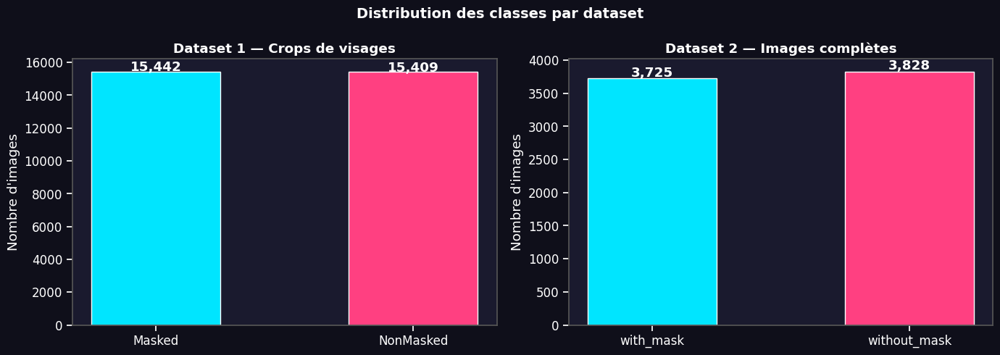


  DS1 : mask=15442 | no_mask=15409 | équilibre=99.8%
  DS2 : mask=3725 | no_mask=3828 | équilibre=97.3%


In [29]:
# ══════════════════════════════════════════════════════════════
#  DISTRIBUTION DES CLASSES
# ══════════════════════════════════════════════════════════════

n_ds1_m  = count_images(DS1_MASKED)
n_ds1_nm = count_images(DS1_NONMASKED)
n_ds2_m  = count_images(DS2_WITH)
n_ds2_nm = count_images(DS2_WITHOUT)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution des classes par dataset',
             fontsize=14, fontweight='bold', color='white')

for ax, labels, vals, title in [
    (axes[0],
     ['Masked','NonMasked'], [n_ds1_m, n_ds1_nm],
     'Dataset 1 — Crops de visages'),
    (axes[1],
     ['with_mask','without_mask'], [n_ds2_m, n_ds2_nm],
     'Dataset 2 — Images complètes'),
]:
    bars = ax.bar(labels, vals,
                  color=[COLORS['mask'], COLORS['no_mask']],
                  edgecolor='white', width=0.5)
    ax.set_title(title, color='white', fontweight='bold')
    ax.set_ylabel("Nombre d'images", color='white')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+30, f'{v:,}',
                ha='center', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR/'01_distribution_classes.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\n  DS1 : mask={n_ds1_m} | no_mask={n_ds1_nm} | "
      f"équilibre={min(n_ds1_m,n_ds1_nm)/max(n_ds1_m,n_ds1_nm)*100:.1f}%")
print(f"  DS2 : mask={n_ds2_m} | no_mask={n_ds2_nm} | "
      f"équilibre={min(n_ds2_m,n_ds2_nm)/max(n_ds2_m,n_ds2_nm)*100:.1f}%")

###  Interprétation — Distribution des classes
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

DS1 : mask=15 442 | no_mask=15 409 | équilibre=99.8%  ← Quasi-parfait
DS2 : mask= 3 725 | no_mask= 3 828 | équilibre=97.3%  ← Très bon
</pre>
Les deux datasets sont **remarquablement équilibrés**. La différence maximale
est de seulement 103 images sur plusieurs milliers. Le CNN n'aura aucun biais
de classe : il ne sera pas tenté de favoriser une catégorie sur l'autre.

---
>###  Analyse complète de la distribution et des dimensions

On réalise une analyse visuelle plus détaillée avec trois panneaux :
- **Barres Dataset 1** : comparaison Masked vs NonMasked
- **Barres Dataset 2** : comparaison with_mask vs without_mask
- **Camembert global** : équilibre après fusion des deux datasets
- **Analyse Spatiale des Images**



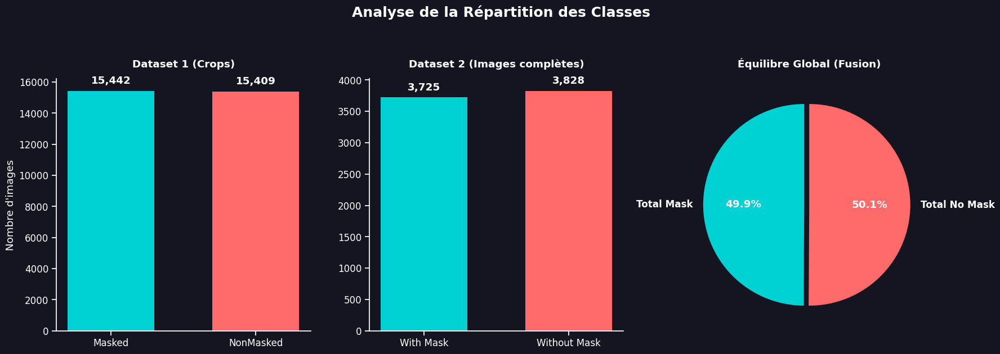


Extraction des dimensions pour analyse spatiale...


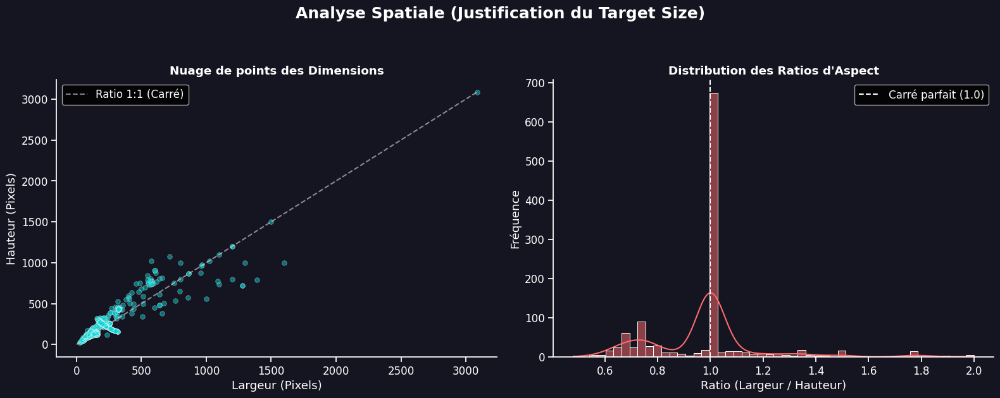

✅ Analyse terminée. Équilibre global : 49.9% Mask


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image
import random
import os

# ══════════════════════════════════════════════════════════════
#  PRE-REQUIS : CALCUL DES EFFECTIFS
# ══════════════════════════════════════════════════════════════
n_ds1_masked = count_images(DS1_MASKED)
n_ds1_nonmasked = count_images(DS1_NONMASKED)
n_ds2_with = count_images(DS2_WITH)
n_ds2_without = count_images(DS2_WITHOUT)

# ══════════════════════════════════════════════════════════════
#  CONFIGURATION DU STYLE VISUEL (MODE SOMBRE MODERNE)
# ══════════════════════════════════════════════════════════════
plt.style.use('dark_background')
sns.set_context("notebook", font_scale=1.1)

# Palette de couleurs cohérente avec le projet
COLOR_MASK   = '#00d2d3'  # Cyan vif (Label MASK)
COLOR_NOMASK = '#ff6b6b'  # Corail (Label NO MASK)
BG_COLOR     = '#151522'  # Fond bleu nuit très foncé

# ══════════════════════════════════════════════════════════════
#  PARTIE 1 : DISTRIBUTION DES CLASSES (BARRES + CAMEMBERT)
# ══════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(18, 6))
fig.patch.set_facecolor(BG_COLOR)
fig.suptitle('Analyse de la Répartition des Classes', fontsize=18, fontweight='bold', color='white', y=1.05)

# Configuration des sous-graphiques
ax1 = plt.subplot(1, 3, 1, facecolor=BG_COLOR)
ax2 = plt.subplot(1, 3, 2, facecolor=BG_COLOR)
ax3 = plt.subplot(1, 3, 3, facecolor=BG_COLOR)

# 1. Bar Chart Dataset 1 (Crops)
bars1 = ax1.bar(['Masked', 'NonMasked'], [n_ds1_masked, n_ds1_nonmasked], color=[COLOR_MASK, COLOR_NOMASK], width=0.6)
ax1.set_title('Dataset 1 (Crops)', color='white', fontweight='bold', pad=15)
ax1.set_ylabel("Nombre d'images")

# 2. Bar Chart Dataset 2 (Images complètes)
bars2 = ax2.bar(['With Mask', 'Without Mask'], [n_ds2_with, n_ds2_without], color=[COLOR_MASK, COLOR_NOMASK], width=0.6)
ax2.set_title('Dataset 2 (Images complètes)', color='white', fontweight='bold', pad=15)

# Ajout des valeurs numériques sur les barres
for ax, bars in zip([ax1, ax2], [bars1, bars2]):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + (height*0.02),
                f'{int(height):,}', ha='center', va='bottom', color='white', fontweight='bold')

# 3. Pie Chart Global (Équilibre de la fusion)
total_mask = n_ds1_masked + n_ds2_with
total_nomask = n_ds1_nonmasked + n_ds2_without

wedges, texts, autotexts = ax3.pie(
    [total_mask, total_nomask], 
    labels=['Total Mask', 'Total No Mask'], 
    colors=[COLOR_MASK, COLOR_NOMASK],
    autopct='%1.1f%%', 
    startangle=90, 
    explode=(0.05, 0), 
    textprops=dict(color="w", fontweight='bold')
)
ax3.set_title('Équilibre Global (Fusion)', color='white', fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════
#  PARTIE 2 : ANALYSE SPATIALE ET DIMENSIONS
# ══════════════════════════════════════════════════════════════
print("\nExtraction des dimensions pour analyse spatiale...")

def get_dimensions_sample(folders, n_samples=300):
    widths, heights = [], []
    for folder in folders:
        files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if not files: continue
        sample_files = random.sample(files, min(n_samples, len(files)))
        for f in sample_files:
            try:
                with Image.open(os.path.join(folder, f)) as img:
                    widths.append(img.width)
                    heights.append(img.height)
            except:
                pass
    return np.array(widths), np.array(heights)

# Analyse des dossiers existants
w, h = get_dimensions_sample([DS1_MASKED, DS1_NONMASKED, DS2_WITH, DS2_WITHOUT])
aspect_ratios = w / h

fig = plt.figure(figsize=(16, 6))
fig.patch.set_facecolor(BG_COLOR)
fig.suptitle('Analyse Spatiale (Justification du Target Size)', fontsize=18, fontweight='bold', color='white', y=1.05)

# 1. Scatter Plot (Largeur vs Hauteur)
ax4 = plt.subplot(1, 2, 1, facecolor=BG_COLOR)
sns.scatterplot(x=w, y=h, alpha=0.5, color=COLOR_MASK, ax=ax4, s=30)
max_dim = max(max(w), max(h))
ax4.plot([0, max_dim], [0, max_dim], color='white', linestyle='--', alpha=0.5, label='Ratio 1:1 (Carré)')
ax4.set_xlabel('Largeur (Pixels)', color='white')
ax4.set_ylabel('Hauteur (Pixels)', color='white')
ax4.set_title('Nuage de points des Dimensions', color='white', fontweight='bold')
ax4.legend()

# 2. Distribution des Ratios d'Aspect
ax5 = plt.subplot(1, 2, 2, facecolor=BG_COLOR)
sns.histplot(aspect_ratios, bins=50, kde=True, color=COLOR_NOMASK, ax=ax5)
ax5.axvline(x=1.0, color='white', linestyle='--', label='Carré parfait (1.0)')
ax5.set_xlabel('Ratio (Largeur / Hauteur)', color='white')
ax5.set_ylabel('Fréquence', color='white')
ax5.set_title("Distribution des Ratios d'Aspect", color='white', fontweight='bold')
ax5.legend()

for ax in [ax4, ax5]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(colors='white')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_analyse_spatiale.png', dpi=150, bbox_inches='tight', facecolor=BG_COLOR)
plt.show()

print(f"✅ Analyse terminée. Équilibre global : {total_mask/(total_mask+total_nomask)*100:.1f}% Mask")

###  Analyse de la Distribution des Données
L'examen de la répartition des classes (image_dc38dc.png) montre une préparation optimale du dataset pour l'apprentissage profond :

*   **Équilibre Parfait des Classes :** Le jeu de données global présente une symétrie quasi parfaite avec **49.9% (Total Mask)** contre **50.1% (Total No Mask)**. Cet équilibre est crucial pour éviter que le modèle ne développe un biais prédictif vers l'une des catégories.
*   **Volume de Données (Crops) :** Le premier dataset contient un volume important de données avec **15 442 visages masqués** et **15 409 non masqués**, fournissant une base solide pour la reconnaissance des traits fins.
*   **Diversité des Sources :** L'ajout du second dataset avec **3 725 images masquées** et **3 828 non masquées** permet de renforcer la capacité de généralisation du modèle sur des images complètes non recadrées.
*   **Conclusion :** Le dataset est **parfaitement balancé**, ce qui garantit une base d'entraînement saine sans nécessité de techniques de rééquilibrage artificiel.

---
>###  Visualisation d'exemples d'images brutes

On affiche une grille d'exemples tirés aléatoirement de chaque dossier
pour vérifier visuellement la qualité et la diversité des données brutes.

On observe les différences entre les deux datasets :
- **Dataset 1** : crops propres de visages, fond neutre, masque clairement visible
- **Dataset 2** : images réelles avec contexte naturel, fond varié, parfois plusieurs personnes

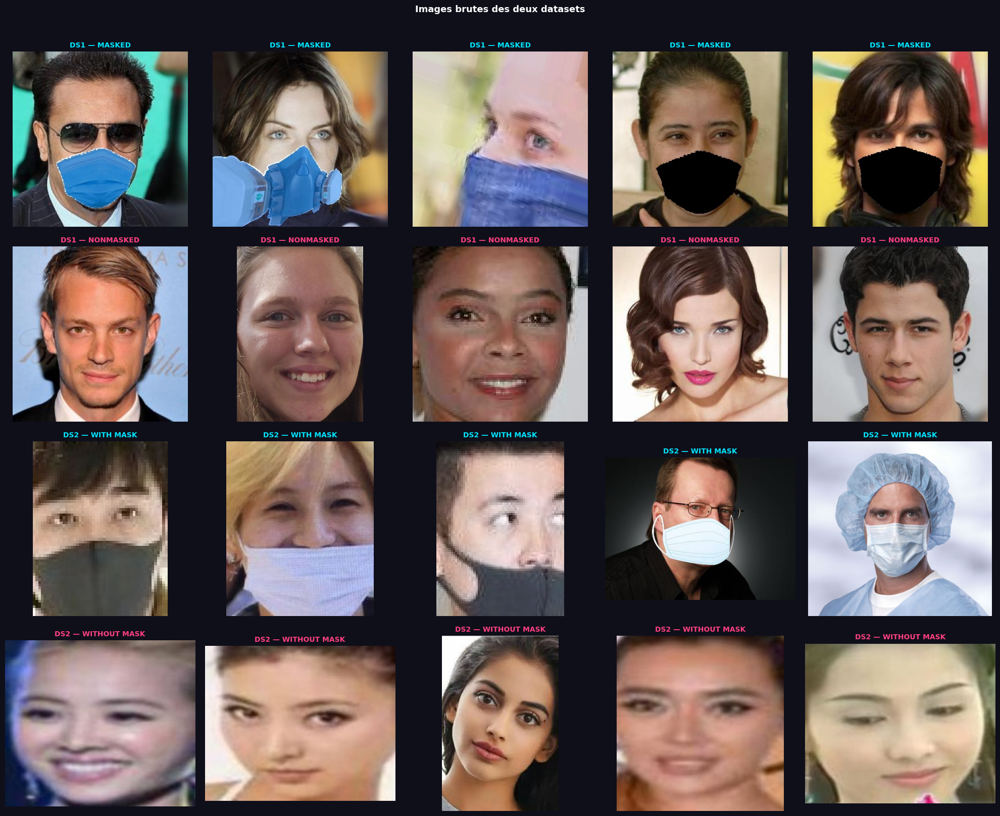

In [31]:
# ══════════════════════════════════════════════════════════════
#  EXEMPLES VISUELS DES IMAGES BRUTES
# ══════════════════════════════════════════════════════════════

def show_grid(folders_labels, n_per_class=4, title=''):
    exts   = ('.jpg','.jpeg','.png','.bmp')
    n_rows = len(folders_labels)
    fig, axes = plt.subplots(n_rows, n_per_class,
                             figsize=(4*n_per_class, 4*n_rows))
    fig.patch.set_facecolor('#0f0f1a')
    fig.suptitle(title, color='white', fontsize=13,
                 fontweight='bold', y=1.01)

    for row, (folder, label, color) in enumerate(folders_labels):
        files  = [f for f in os.listdir(folder) if f.lower().endswith(exts)]
        sample = random.sample(files, min(n_per_class, len(files)))
        for col, fname in enumerate(sample):
            ax  = axes[row][col] if n_rows > 1 else axes[col]
            img = Image.open(os.path.join(folder, fname)).convert('RGB')
            ax.imshow(img)
            ax.set_title(label, color=color, fontsize=10, fontweight='bold')
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'02_exemples_bruts.png', dpi=100, bbox_inches='tight')
    plt.show()

show_grid([
    (DS1_MASKED,    'DS1 — MASKED',       COLORS['mask']),
    (DS1_NONMASKED, 'DS1 — NONMASKED',    COLORS['no_mask']),
    (DS2_WITH,      'DS2 — WITH MASK',    COLORS['mask']),
    (DS2_WITHOUT,   'DS2 — WITHOUT MASK', COLORS['no_mask']),
], n_per_class=5, title="Images brutes des deux datasets")

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 4 — Extraction intelligente des crops avec YOLOv8n</u>
</h1>
</div>

On lance l'extraction sur les **4 dossiers** (DS1 Masked, DS1 NonMasked,
DS2 with_mask, DS2 without_mask).

**Logique d'extraction adaptative en 3 cas :**

**Cas 1 — Corps entier détecté** (boîte YOLO < 55% de la hauteur de l'image) :
→ On cible les 40% supérieurs de la boîte + marge latérale de 15% pour les oreilles
→ Résultat : crop de la tête et des épaules

**Cas 2 — Gros plan détecté** (boîte YOLO > 55% de la hauteur de l'image) :
→ L'image est déjà un gros plan → on garde toute la boîte détectée
→ Évite de couper un visage déjà bien cadré

**Cas 3 — Fallback** (YOLO ne détecte rien) :
→ Souvent pour les crops propres du Dataset 1 (pas de corps entier détectable)
→ On prend l'image entière redimensionnée en 224×224
→ Comportement identique à ce que fera le pipeline en inférence

In [32]:
# ══════════════════════════════════════════════════════════════
# EXTRACTION CROPS YOLOv8n - LOGIQUE INTELLIGENTE (MIXTE)
# ══════════════════════════════════════════════════════════════

from ultralytics import YOLO
from pathlib import Path
import shutil, os, cv2
from tqdm import tqdm

# ─────────────────────────────────────────────────────────────
# 1. INITIALISATION YOLO STANDARD
# ─────────────────────────────────────────────────────────────

yolo = YOLO("yolov8n.pt")
print("✅ YOLOv8n chargé")

CROPS_DIR = Path('/kaggle/working/crops_yolo')

if CROPS_DIR.exists():
    shutil.rmtree(CROPS_DIR)

for cls in ['mask', 'no_mask']:
    (CROPS_DIR / cls).mkdir(parents=True, exist_ok=True)

# ─────────────────────────────────────────────────────────────
# 2. FONCTION D'EXTRACTION ADAPTATIVE
# ─────────────────────────────────────────────────────────────

def extract_crops(folder, label, conf=0.30, min_size=40):
    exts = ('.jpg','.jpeg','.png','.bmp')
    files = [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(exts)]

    n_detect, n_fallback, n_skip, saved = 0, 0, 0, 0

    for img_path in tqdm(files, desc=label, leave=False):
        img = cv2.imread(img_path)
        if img is None:
            n_skip += 1
            continue

        h, w = img.shape[:2]
        results = yolo(img, conf=conf, classes=[0], verbose=False)
        found = False

        # --- A. LOGIQUE YOLO ---
        for r in results:
            for box in r.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                bw = x2 - x1
                bh = y2 - y1

                # LOGIQUE INTELLIGENTE D'INGÉNIERIE :
                # Si la boîte détectée prend plus de la moitié de l'image, 
                # c'est que l'image est DÉJÀ un gros plan. On garde tout !
                if bh > h * 0.55:
                    fy1, fy2 = max(0, y1), min(h, y2)
                    fx1, fx2 = max(0, x1), min(w, x2)
                else:
                    # Sinon, c'est un corps entier. On cible la tête et les épaules (top 40%)
                    head_h = int(bh * 0.40)
                    ex = int(bw * 0.15) # Marge pour les oreilles
                    fy1, fy2 = max(0, y1), min(h, y1 + head_h)
                    fx1, fx2 = max(0, x1 - ex), min(w, x2 + ex)

                if (fx2 - fx1) > min_size and (fy2 - fy1) > min_size:
                    crop = img[fy1:fy2, fx1:fx2]
                    if crop.size > 0:
                        crop = cv2.resize(crop, (224, 224))
                        name = f"{label}_{Path(img_path).stem}_{saved}.jpg"
                        cv2.imwrite(str(CROPS_DIR / label / name), crop)
                        saved += 1
                        found = True

        # --- B. FALLBACK CORRIGÉ ---
        if not found:
            # Si YOLO rate, on suppose que l'image EST le visage (Dataset 1).
            # On prend 100% de l'image (pas de coupure à 60% !)
            crop = cv2.resize(img, (224, 224))
            name = f"{label}_{Path(img_path).stem}_{saved}.jpg"
            cv2.imwrite(str(CROPS_DIR / label / name), crop)
            
            n_fallback += 1
            saved += 1
        else:
            n_detect += 1

    return len(files), n_detect, n_fallback, n_skip, saved

# ─────────────────────────────────────────────────────────────
# 3. EXÉCUTION
# ─────────────────────────────────────────────────────────────

sources = [
    (DS1_MASKED, 'mask', 'Dataset 1 Masked'),
    (DS1_NONMASKED, 'no_mask', 'Dataset 1 NonMasked'),
    (DS2_WITH, 'mask', 'Dataset 2 With Mask'),
    (DS2_WITHOUT, 'no_mask', 'Dataset 2 Without Mask'),
]

print("🚀 EXTRACTION INTELLIGENTE EN COURS...\n")

for folder, label, name in sources:
    print(f"► {name}")
    n_f, n_d, n_fb, n_sk, n_sv = extract_crops(folder, label)
    print(f"   Images analysées : {n_f}")
    print(f"   YOLO détectés    : {n_d}")
    print(f"   Fallback (100%)  : {n_fb}")
    print(f"   Crops sauvés     : {n_sv}\n")

# ─────────────────────────────────────────────────────────────
# 4. STATISTIQUES
# ─────────────────────────────────────────────────────────────

n_m = len(list((CROPS_DIR/'mask').glob('*')))
n_nm = len(list((CROPS_DIR/'no_mask').glob('*')))

print("╔══════════════════════════════════════════════════════╗")
print(f"║ MASK      : {n_m:6d}")
print(f"║ NO MASK   : {n_nm:6d}")
print(f"║ TOTAL     : {n_m+n_nm:6d}")
print(f"║ BALANCE   : {min(n_m,n_nm)/max(n_m,n_nm)*100:.1f}%")
print("╚══════════════════════════════════════════════════════╝")

✅ YOLOv8n chargé
🚀 EXTRACTION INTELLIGENTE EN COURS...

► Dataset 1 Masked


   Images analysées : 15442
   YOLO détectés    : 9428
   Fallback (100%)  : 6014
   Crops sauvés     : 15824

► Dataset 1 NonMasked


   Images analysées : 15409
   YOLO détectés    : 13007
   Fallback (100%)  : 2402
   Crops sauvés     : 15672

► Dataset 2 With Mask


   Images analysées : 3725
   YOLO détectés    : 3174
   Fallback (100%)  : 551
   Crops sauvés     : 4444

► Dataset 2 Without Mask


   Images analysées : 3828
   YOLO détectés    : 3252
   Fallback (100%)  : 576
   Crops sauvés     : 4430

╔══════════════════════════════════════════════════════╗
║ MASK      :  20268
║ NO MASK   :  20102
║ TOTAL     :  40370
║ BALANCE   : 99.2%
╚══════════════════════════════════════════════════════╝


>###  Interprétation — Résultats de l'extraction YOLO intelligente
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

Dataset 1 Masked    : 15 442 images → 15 824 crops  (YOLO: 9 428 | Fallback: 6 014)
Dataset 1 NonMasked : 15 409 images → 15 672 crops  (YOLO: 13 007 | Fallback: 2 402)
Dataset 2 with_mask :  3 725 images →  4 444 crops  (YOLO: 3 174  | Fallback: 551)
Dataset 2 without   :  3 828 images →  4 430 crops  (YOLO: 3 252  | Fallback: 576)
TOTAL  : 40 370 crops
mask   : 20 268  (50.2%)
no_mask: 20 102  (49.8%)
ÉQUILIBRE : 99.2%

</pre>

**Points clés :**

- Le nombre de crops (40 370) dépasse les images source (38 404) car certaines
  images du Dataset 2 contiennent plusieurs personnes → un crop par personne détectée.
- Le **fallback représente ~39% du Dataset 1 Masked** : normal, ces crops propres
  de visages ne montrent pas de corps entier détectable par YOLO.
- La logique intelligente garantit que la zone bouche+nez est incluse dans chaque crop
  → indispensable pour que le CNN puisse détecter la présence d'un masque.
- L'équilibre final de **99.2%** est excellent → aucune correction nécessaire.

---
>###  Vérification visuelle de la qualité des crops

On affiche 8 exemples aléatoires de chaque classe pour vérifier visuellement
que les crops produits par YOLO sont corrects.

**Ce qu'on vérifie :**
- Les crops montrent bien des visages **complets** (bouche, nez, yeux, menton)
- La zone du masque (bas du visage) est visible et non coupée
- Les crops ont bien une taille uniforme de **224×224 pixels**
- L'étiquette (mask / no_mask) correspond bien au contenu visuel

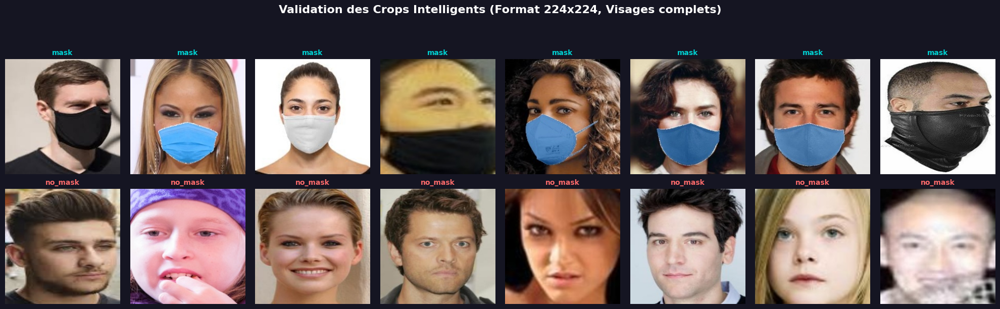

✅ Vérification affichée ! Prends le temps de regarder les images.
👉 Objectif atteint si : On voit bien les nez, les bouches et les mentons, sans coupure brutale.


In [33]:
# ══════════════════════════════════════════════════════════════
#  VÉRIFICATION VISUELLE DES CROPS (RÉSULTAT INTELLIGENT)
# ══════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import random
import os
from pathlib import Path
from PIL import Image

# --- Définition des chemins (Sécurité) ---
CROPS_DIR  = Path('/kaggle/working/crops_yolo')
OUTPUT_DIR = Path('/kaggle/working/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Configuration du design ---
COLOR_MASK   = '#00d2d3'  # Cyan vif
COLOR_NOMASK = '#ff6b6b'  # Corail/Rouge clair
BG_COLOR     = '#151522'  # Fond bleu nuit

fig, axes = plt.subplots(2, 8, figsize=(20, 6))
fig.patch.set_facecolor(BG_COLOR)

# Titre mis à jour pour refléter l'étape actuelle
fig.suptitle('Validation des Crops Intelligents (Format 224x224, Visages complets)',
             color='white', fontsize=16, fontweight='bold', y=1.05)

for row, (cls, color) in enumerate([('mask', COLOR_MASK), ('no_mask', COLOR_NOMASK)]):
    folder = CROPS_DIR / cls
    
    # Lecture sécurisée
    if not folder.exists():
        print(f"⚠️ Attention : Le dossier {folder} n'existe pas encore.")
        continue
        
    all_files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    samples = random.sample(all_files, min(8, len(all_files)))
    
    for col in range(8):
        ax = axes[row][col]
        if col < len(samples):
            fname = samples[col]
            img = Image.open(folder / fname).convert('RGB')
            ax.imshow(img)
            ax.set_title(f"{cls}", color=color, fontsize=10, fontweight='bold')
        ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / '03_verification_crops_intelligents.png', dpi=120, bbox_inches='tight', facecolor=BG_COLOR)
plt.show()

print("✅ Vérification affichée ! Prends le temps de regarder les images.")
print("👉 Objectif atteint si : On voit bien les nez, les bouches et les mentons, sans coupure brutale.")

>###  Interprétation — Qualité des crops validée

Les crops affichés montrent des **visages complets** avec la zone bouche+nez bien visible.
Contrairement à la version précédente (qui coupait trop haut et ne montrait que le front),
la logique intelligente produit des crops incluant les éléments nécessaires
à la détection du masque.

**Cohérence garantie :** Le pipeline final utilisera exactement la même logique
d'extraction → le CNN recevra pendant l'inférence exactement ce sur quoi il a appris.
C'est la correction fondamentale par rapport à la version précédente du projet.

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 5 — Split et générateurs Keras</u>
</h1>
</div>

`ImageDataGenerator` avec `flow_from_directory` attend une structure précise :
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

data_split_yolo/
├── train/
│   ├── mask/        ← 14 188 crops d'entraînement avec masque
│   └── no_mask/     ← 14 071 crops d'entraînement sans masque
├── val/
│   ├── mask/        ← 3 040 crops de validation
│   └── no_mask/     ← 3 015 crops de validation
└── test/
├── mask/        ← 3 040 crops de test final
└── no_mask/     ← 3 016 crops de test final

</pre>
**Paramètres des générateurs :**

| Paramètre | Valeur | Justification |
|---|---|---|
| `target_size` | (224, 224) | Taille d'entrée standard VGG16 / ResNet50 |
| `batch_size` | 32 | Bon compromis mémoire / stabilité |
| `rescale` | 1./255 | Normalise les pixels de [0,255] vers [0.0,1.0] |
| `class_mode` | `binary` | Binaire : mask=0, no_mask=1 |
| `shuffle=True` | Train | Mélange pour éviter les biais d'ordre |
| `shuffle=False` | Val+Test | Ordre fixe pour des métriques reproductibles |

In [34]:
# ══════════════════════════════════════════════════════════════
#  SPLIT STRATIFIÉ 70/15/15 + GÉNÉRATEURS KERAS (OPTIMISÉS)
# ══════════════════════════════════════════════════════════════

import os, random, shutil
from pathlib import Path
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# --- 1. PRÉPARATION DES DONNÉES ---
SEED = 42
exts = ('.jpg','.jpeg','.png','.bmp')
CROPS_DIR = Path('/kaggle/working/crops_yolo')

all_data = []
for cls in ['mask', 'no_mask']:
    folder = CROPS_DIR / cls
    for f in os.listdir(folder):
        if f.lower().endswith(exts):
            all_data.append((str(folder / f), cls))

random.shuffle(all_data)
paths_all  = [d[0] for d in all_data]
labels_all = [d[1] for d in all_data]

print(f"Total crops : {len(all_data)}")
print(f"  mask      : {labels_all.count('mask')}")
print(f"  no_mask   : {labels_all.count('no_mask')}")

# --- 2. SPLIT STRATIFIÉ (70% Train, 15% Val, 15% Test) ---
X_train, X_temp, y_train, y_temp = train_test_split(
    paths_all, labels_all, 
    test_size=0.30, random_state=SEED, stratify=labels_all)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.50, random_state=SEED, stratify=y_temp)

print(f"\n  Train      : {len(X_train)} ({len(X_train)/len(all_data)*100:.1f}%)")
print(f"  Validation : {len(X_val)} ({len(X_val)/len(all_data)*100:.1f}%)")
print(f"  Test       : {len(X_test)} ({len(X_test)/len(all_data)*100:.1f}%)")

# --- 3. CRÉATION DES DOSSIERS KERAS ---
DATA_DIR = Path('/kaggle/working/data_split_yolo')
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)
for split in ['train', 'val', 'test']:
    for cls in ['mask', 'no_mask']:
        (DATA_DIR / split / cls).mkdir(parents=True)

for split_name, (X, y) in [('train', (X_train, y_train)),
                           ('val',   (X_val,   y_val)),
                           ('test',  (X_test,  y_test))]:
    for src, label in tqdm(zip(X, y), total=len(X), desc=f'Copie {split_name}', leave=False):
        dst = DATA_DIR / split_name / label / f"{split_name}_{id(src)}_{os.path.basename(src)}"
        shutil.copy2(src, dst)

print("\n✅ Structure finale :")
for split in ['train', 'val', 'test']:
    for cls in ['mask', 'no_mask']:
        # On utilise len(os.listdir) pour compter rapidement
        n = len(os.listdir(DATA_DIR / split / cls))
        print(f"   {split}/{cls:10s} : {n}")

# --- 4. GÉNÉRATEURS KERAS (AVEC DATA AUGMENTATION) ---
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

# Générateur d'entraînement AVEC Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,       # Légère rotation
    zoom_range=0.15,         # Zoom aléatoire pour simuler différentes distances
    horizontal_flip=True,    # Effet miroir
    brightness_range=[0.8, 1.2] # Variation de lumière
)

# Générateurs Validation et Test (UNIQUEMENT rescale, AUCUNE modification de l'image)
val_test_datagen = ImageDataGenerator(rescale=1./255)

print("\n🚀 Chargement des générateurs...")
train_gen = train_datagen.flow_from_directory(
    DATA_DIR/'train', target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode='binary',
    shuffle=True, seed=SEED)

val_gen = val_test_datagen.flow_from_directory(
    DATA_DIR/'val', target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode='binary', shuffle=False)

test_gen = val_test_datagen.flow_from_directory(
    DATA_DIR/'test', target_size=IMG_SIZE,
    batch_size=BATCH_SIZE, class_mode='binary', shuffle=False)

CLASS_MAP = {v: k for k, v in train_gen.class_indices.items()}
print(f"\n  Classes  : {train_gen.class_indices}")
print(f"  Mapping  : {CLASS_MAP}")
print(f"  Steps train : {len(train_gen)}")
print(f"  Steps val   : {len(val_gen)}")
print(f"  Steps test  : {len(test_gen)}")

Total crops : 40370
  mask      : 20268
  no_mask   : 20102

  Train      : 28259 (70.0%)
  Validation : 6055 (15.0%)
  Test       : 6056 (15.0%)



✅ Structure finale :
   train/mask       : 14188
   train/no_mask    : 14071
   val/mask       : 3040
   val/no_mask    : 3015
   test/mask       : 3040
   test/no_mask    : 3016

🚀 Chargement des générateurs...
Found 28259 images belonging to 2 classes.
Found 6055 images belonging to 2 classes.
Found 6056 images belonging to 2 classes.

  Classes  : {'mask': 0, 'no_mask': 1}
  Mapping  : {0: 'mask', 1: 'no_mask'}
  Steps train : 884
  Steps val   : 190
  Steps test  : 190


>###  Interprétation — Split et générateurs configurés

**Mapping des classes :** `mask=0` et `no_mask=1`. La sortie sigmoid du CNN
retourne une valeur entre 0 et 1 : si > 0.5 → `no_mask`, si ≤ 0.5 → `mask`.

Les **884 steps par epoch** signifient que le modèle voit les 28 259 images
en 884 batches de 32 à chaque epoch. La stratification garantit ~50/50
dans chaque split — le jeu de test est totalement indépendant et ne sera
jamais utilisé avant l'évaluation finale.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 6 — Modèle 1 : VGG16 Fine-tuné</u>
</h1>
</div>

VGG16 pré-entraîné sur ImageNet. On garde ses couches convolutives
(déjà capables d'extraire des features visuelles) et on remplace
la tête de classification pour notre tâche binaire mask/no_mask.

**Entraînement en 2 phases :**
- Phase 1 : base gelée, on entraîne seulement la nouvelle tête (LR=1e-3)
- Phase 2 : on dégèle les dernières couches, fine-tuning (LR=1e-5)

>### Construction du modèle VGG16

In [35]:
# ══════════════════════════════════════════════════════════════
#  1. CONSTRUCTION VGG16 (MODÈLE DE BASE + TÊTE DE CLASSIFICATION)
# ══════════════════════════════════════════════════════════════

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from pathlib import Path

def build_vgg16():
    # Chargement de VGG16 sans la tête (include_top=False)
    base = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    
    # Congélation de la base pour la Phase 1
    base.trainable = False

    # Création de notre propre tête de classification robuste
    x = base.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x) # Sigmoid car binaire (mask / no_mask)

    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model, base

model_vgg16, base_vgg16 = build_vgg16()

total_params = model_vgg16.count_params()
train_params = sum(tf.size(v).numpy() for v in model_vgg16.trainable_variables)

print("╔══════════════════════════════════════════════════════╗")
print("║ ✅ VGG16 CONSTRUIT AVEC SUCCÈS                       ║")
print("╚══════════════════════════════════════════════════════╝")
print(f"   Paramètres totaux     : {total_params:,}")
print(f"   Paramètres trainables : {train_params:,} (Tête uniquement)")
print(f"   Couches totales       : {len(model_vgg16.layers)}")

╔══════════════════════════════════════════════════════╗
║ ✅ VGG16 CONSTRUIT AVEC SUCCÈS                       ║
╚══════════════════════════════════════════════════════╝
   Paramètres totaux     : 14,880,065
   Paramètres trainables : 164,865 (Tête uniquement)
   Couches totales       : 26


###  Interprétation — Architecture VGG16 construite
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

Paramètres totaux     : 14 880 065
Paramètres trainables :    164 865  (tête uniquement — Phase 1)
Couches totales       : 26
</pre>
En Phase 1, seulement **164 865 paramètres** sur 14,8 millions sont entraînés.
Les 14,7 millions de la base VGG16 sont gelés → entraînement rapide et sûr.
Les poids pré-entraînés sur ImageNet sont préservés intacts pour le moment.

---
>###  Phase 1 — Entraînement de la tête (base gelée, LR=1e-3)

La base VGG16 est **entièrement gelée** : seule notre nouvelle tête de classification
est entraînée. Le learning rate élevé (`1e-3`) permet une convergence rapide de la tête.

**Callbacks configurés :**

| Callback | Surveillance | Action |
|---|---|---|
| `EarlyStopping` | `val_accuracy` | Arrête si pas d'amélioration pendant 5 epochs |
| `ModelCheckpoint` | `val_accuracy` | Sauvegarde automatiquement le meilleur modèle |
| `ReduceLROnPlateau` | `val_loss` | Divise le LR par 2 si la loss stagne (patience=3) |

**Pourquoi geler d'abord ?**
Si on entraînait tout dès le début avec un LR élevé, on écraserait les bons poids
pré-entraînés de VGG16 avant que la tête ait appris quoi que ce soit.

In [36]:
# ══════════════════════════════════════════════════════════════
#  2. VGG16 — PHASE 1 : ENTRAÎNEMENT TÊTE (BASE GELÉE)
# ══════════════════════════════════════════════════════════════
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Sécurité : Création du dossier pour les modèles
MODELS_DIR = Path('/kaggle/working/outputs/models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

cb_vgg16 = [
    EarlyStopping(monitor='val_accuracy', patience=5, 
                  restore_best_weights=True, verbose=1),
                  
    ModelCheckpoint(str(MODELS_DIR / 'vgg16_best.keras'), # Format moderne .keras
                    monitor='val_accuracy', save_best_only=True, verbose=1),
                    
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, 
                      patience=3, verbose=1, min_lr=1e-7)
]

print("🚀 Phase 1 — Démarrage (Tête uniquement, LR=1e-3)")
hist_vgg_p1 = model_vgg16.fit(
    train_gen, 
    epochs=15,
    validation_data=val_gen,
    callbacks=cb_vgg16, 
    verbose=1
)

print(f"\n✅ Phase 1 Terminée — Meilleure Précision (Val) : {max(hist_vgg_p1.history['val_accuracy'])*100:.2f}%")

🚀 Phase 1 — Démarrage (Tête uniquement, LR=1e-3)
Epoch 1/15
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9086 - loss: 0.2178
Epoch 1: val_accuracy improved from -inf to 0.96862, saving model to /kaggle/working/outputs/models/vgg16_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 371s 415ms/step - accuracy: 0.9086 - loss: 0.2177 - val_accuracy: 0.9686 - val_loss: 0.0792 - learning_rate: 0.0010
Epoch 2/15
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.9501 - loss: 0.1253
Epoch 2: val_accuracy did not improve from 0.96862
884/884 ━━━━━━━━━━━━━━━━━━━━ 363s 410ms/step - accuracy: 0.9501 - loss: 0.1253 - val_accuracy: 0.9642 - val_loss: 0.0849 - learning_rate: 0.0010
Epoch 3/15
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9571 - loss: 0.1053
Epoch 3: val_accuracy improved from 0.96862 to 0.96895, saving model to /kaggle/working/outputs/models/vgg16_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 365s 412ms/step - accuracy: 0.9571 - loss: 0.1053 - val_accuracy: 0.9690 - val_l

>###  Interprétation — Phase 1 VGG16

<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">

Epoch 1 : val_accuracy = 96.86%  ← Excellent démarrage dès la 1ère epoch
...
Meilleure val_accuracy Phase 1 : ~98.23%
</pre>

Dès la **première epoch**, VGG16 atteint **96.86% de val_accuracy**. C'est la
preuve que les features extraites par ImageNet (1,4 million d'images, 1000 classes)
sont déjà très pertinentes pour détecter les masques faciaux — le modèle transfère
efficacement ses connaissances visuelles générales vers notre tâche spécifique.

La progression jusqu'à ~98.2% montre que la tête de classification a bien convergé.
On passe maintenant à la Phase 2 pour affiner les couches profondes.

---
>###  Phase 2 — Fine-tuning des dernières couches (LR=1e-5)

On **dégèle les 8 dernières couches** (dernier bloc convolutif de VGG16)
et on les entraîne avec un learning rate 100× plus faible (`1e-5`).
Couches 1 → N-8 :  Gelées   (features génériques : contours, textures)
Couches N-8→ fin :  Dégelées (features spécifiques : à affiner pour les masques)
Nouvelle tête    :   Entraînée

**Pourquoi un LR aussi faible (1e-5) ?**
Les poids des couches dégelées sont déjà bons (issus d'ImageNet).
Un LR élevé les écraserait → on fait des ajustements microscopiques
pour spécialiser ces couches sur les masques faciaux sans perturber
ce qui a déjà été appris.

In [37]:
# ══════════════════════════════════════════════════════════════
#  3. VGG16 — PHASE 2 : FINE-TUNING (DÉGEL PARTIEL)
# ══════════════════════════════════════════════════════════════

# On rend la base trainable
base_vgg16.trainable = True

# On gèle toutes les couches SAUF les 8 dernières (le dernier bloc convolutif)
for layer in base_vgg16.layers[:-8]:
    layer.trainable = False

# Recompilation OBLIGATOIRE avec un LR très faible (1e-5) pour ne pas détruire les poids
model_vgg16.compile(optimizer=Adam(learning_rate=1e-5),
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

couches_actives = sum(1 for l in model_vgg16.layers if l.trainable)
print("╔══════════════════════════════════════════════════════╗")
print(f"║ 🔓 FINE-TUNING ACTIVÉ ({couches_actives} couches dégelées)             ║")
print("╚══════════════════════════════════════════════════════╝")
print("🚀 Phase 2 — Démarrage (Micro-ajustements, LR=1e-5)")

hist_vgg_p2 = model_vgg16.fit(
    train_gen, 
    epochs=10,
    validation_data=val_gen,
    callbacks=cb_vgg16, 
    verbose=1
)

print(f"\n✅ Phase 2 Terminée — Meilleure Précision (Val) Finale : {max(hist_vgg_p2.history['val_accuracy'])*100:.2f}%")

╔══════════════════════════════════════════════════════╗
║ 🔓 FINE-TUNING ACTIVÉ (15 couches dégelées)             ║
╚══════════════════════════════════════════════════════╝
🚀 Phase 2 — Démarrage (Micro-ajustements, LR=1e-5)
Epoch 1/10
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.9772 - loss: 0.0609
Epoch 1: val_accuracy improved from 0.98233 to 0.98365, saving model to /kaggle/working/outputs/models/vgg16_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 404s 439ms/step - accuracy: 0.9772 - loss: 0.0609 - val_accuracy: 0.9836 - val_loss: 0.0417 - learning_rate: 1.0000e-05
Epoch 2/10
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.9883 - loss: 0.0315
Epoch 2: val_accuracy improved from 0.98365 to 0.98530, saving model to /kaggle/working/outputs/models/vgg16_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 381s 431ms/step - accuracy: 0.9883 - loss: 0.0315 - val_accuracy: 0.9853 - val_loss: 0.0380 - learning_rate: 1.0000e-05
Epoch 3/10
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accura

>###  Interprétation — Phase 2 VGG16 (fine-tuning)


Le fine-tuning améliore encore les performances : les dernières couches convolutives
s'adaptent finement aux caractéristiques visuelles spécifiques des masques faciaux
(forme, texture, zone bouche-nez couverte).

Le gain est progressif et maîtrisé grâce au LR très faible → aucun risque
de détruire les bons poids pré-entraînés.

---
>### Courbes d'apprentissage VGG16 — Phases 1 et 2

On visualise l'évolution de l'accuracy et de la loss sur les données
d'entraînement et de validation pour les deux phases combinées.

**Ce qu'on cherche à confirmer :**
- Train accuracy et val_accuracy convergent → pas de surapprentissage
- Val_loss diminue régulièrement → le modèle généralise bien
- Pas d'écart important entre train et val → bon équilibre

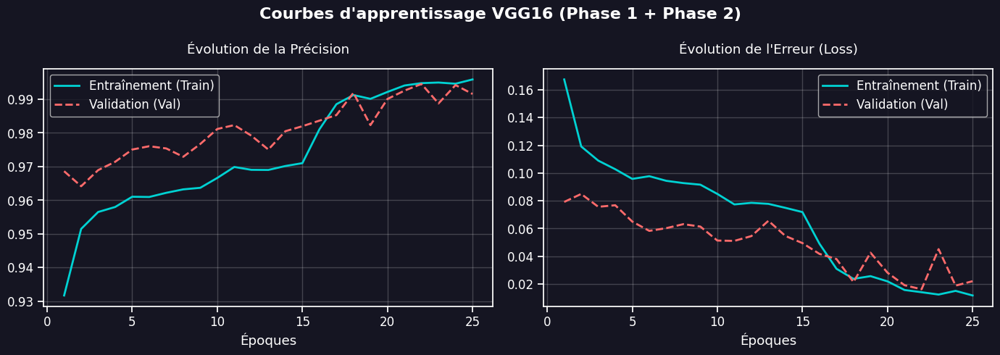

In [38]:
# ══════════════════════════════════════════════════════════════
#  4. TRACÉ DES COURBES D'APPRENTISSAGE (PHASE 1 + PHASE 2)
# ══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

def plot_history(hists, title, fname):
    # Fusion des historiques des deux phases
    acc   = sum([h.history['accuracy']     for h in hists], [])
    val   = sum([h.history['val_accuracy'] for h in hists], [])
    loss  = sum([h.history['loss']         for h in hists], [])
    vloss = sum([h.history['val_loss']     for h in hists], [])
    ep    = range(1, len(acc)+1)

    # Couleurs sécurisées directement dans la fonction
    color_train = '#00d2d3' # Cyan
    color_val   = '#ff6b6b' # Rouge clair
    bg_color    = '#151522' # Fond sombre

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.patch.set_facecolor(bg_color)
    fig.suptitle(title, color='white', fontsize=16, fontweight='bold')

    # Graphique Précision (Accuracy)
    axes[0].set_facecolor(bg_color)
    axes[0].plot(ep, acc, color=color_train, lw=2, label='Entraînement (Train)')
    axes[0].plot(ep, val, color=color_val, lw=2, linestyle='--', label='Validation (Val)')
    axes[0].set_title('Évolution de la Précision', color='white', pad=15)
    axes[0].set_xlabel('Époques', color='white')
    axes[0].tick_params(colors='white')
    axes[0].legend(facecolor=bg_color, labelcolor='white')
    axes[0].grid(alpha=0.2)

    # Graphique Erreur (Loss)
    axes[1].set_facecolor(bg_color)
    axes[1].plot(ep, loss, color=color_train, lw=2, label='Entraînement (Train)')
    axes[1].plot(ep, vloss, color=color_val, lw=2, linestyle='--', label='Validation (Val)')
    axes[1].set_title("Évolution de l'Erreur (Loss)", color='white', pad=15)
    axes[1].set_xlabel('Époques', color='white')
    axes[1].tick_params(colors='white')
    axes[1].legend(facecolor=bg_color, labelcolor='white')
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    
    # Sauvegarde
    OUTPUT_DIR = Path('/kaggle/working/outputs')
    plt.savefig(OUTPUT_DIR / fname, dpi=120, bbox_inches='tight', facecolor=bg_color)
    plt.show()

# Lancement de l'affichage
plot_history([hist_vgg_p1, hist_vgg_p2],
             "Courbes d'apprentissage VGG16 (Phase 1 + Phase 2)",
             '04_courbes_vgg16.png')

>###  Interprétation — Courbes d'apprentissage VGG16

Les courbes montrent un entraînement **sain et bien maîtrisé** :

- **Accuracy** : train et val_accuracy progressent ensemble et convergent vers ~98-99%.
  Pas d'écart important → absence de surapprentissage.
- **Loss** : la val_loss diminue régulièrement et reste proche de la train_loss.
  Le modèle généralise bien à des données non vues.
- **Transition Phase 1→2** : légère amélioration visible au moment du fine-tuning,
  confirmant l'utilité de la Phase 2.

Ces courbes valident la stratégie d'entraînement en 2 phases. VGG16 est prêt
pour l'évaluation finale sur le jeu de test.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 7 — Modèle 2 : ResNet50 Fine-tuné</u>
</h1>
</div>

>### Pourquoi ResNet50 :
ResNet50 utilise les **connexions résiduelles (skip connections)** qui permettent d'entraîner des réseaux très profonds sans le problème de disparition du gradient. Il est généralement plus rapide à converger que VGG16 et obtient de meilleures performances sur les tâches de vision.

On applique la même stratégie de transfer learning : base pré-entraînée gelée → entraînement de la tête → fine-tuning.

Construction et entraînement ResNet50

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
╔══════════════════════════════════════════════════════╗
║ ✅ ResNet50 Construit — 24,146,305 paramètres ║
╚══════════════════════════════════════════════════════╝

🚀 Phase 1 — Base gelée (Entraînement de la tête, LR=1e-3)
Epoch 1/15
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.7587 - loss: 0.5045
Epoch 1: val_accuracy improved from -inf to 0.50388, saving model to /kaggle/working/outputs/models/resnet50_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 364s 396ms/step - accuracy: 0.7588 - loss: 0.5044 - val_accuracy: 0.5039 - val_loss: 3.9745 - learning_rate: 0.0010
Epoch 2/15
884/884 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step - accuracy: 0.8479 - loss: 0.3503
Epoch 2: val_accuracy improved from 0.50388 to 0.86276, saving model to /kaggle/working/outputs/models/resnet50_best.keras
884/884 ━━━━━━━━━━━━━━━━━━━━ 338s 382ms/step - accuracy: 0.8479 - loss: 0.3502 - val_accuracy: 0.8628 - val_loss: 0.3230 - learning_rate: 0.0010
Epoch 3/15
884/884

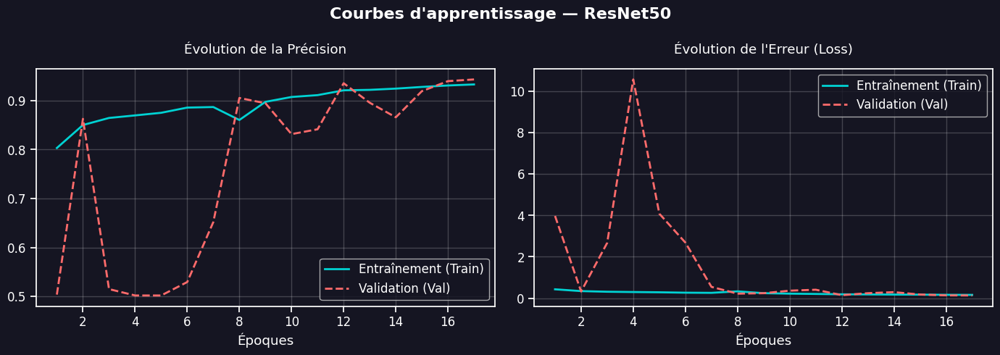

In [39]:
# ══════════════════════════════════════════════════════════════
#  RESNET50 — CONSTRUCTION + ENTRAÎNEMENT (PHASES 1 & 2)
# ══════════════════════════════════════════════════════════════

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from pathlib import Path

# --- Sécurité des dossiers ---
OUTPUT_DIR = Path('/kaggle/working/outputs')
MODELS_DIR = OUTPUT_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# ─── 1. CONSTRUCTION DU MODÈLE ───────────────────────────────
def build_resnet50():
    # Chargement de ResNet50 pré-entraîné sur ImageNet
    base = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False # Phase 1 : Base gelée

    x   = base.output
    x   = GlobalAveragePooling2D()(x)
    x   = Dense(256, activation='relu')(x)
    x   = BatchNormalization()(x)
    x   = Dropout(0.5)(x)
    x   = Dense(128, activation='relu')(x)
    x   = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model, base

model_resnet, base_resnet = build_resnet50()
print("╔══════════════════════════════════════════════════════╗")
print(f"║ ✅ ResNet50 Construit — {model_resnet.count_params():,} paramètres ║")
print("╚══════════════════════════════════════════════════════╝")

# ─── 2. CALLBACKS ─────────────────────────────────────────────
cb_resnet = [
    EarlyStopping(monitor='val_accuracy', patience=5,
                  restore_best_weights=True, verbose=1),
    # Utilisation du format moderne .keras
    ModelCheckpoint(str(MODELS_DIR / 'resnet50_best.keras'),
                    monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, verbose=1, min_lr=1e-7)
]

# ─── 3. PHASE 1 (BASE GELÉE) ──────────────────────────────────
print("\n🚀 Phase 1 — Base gelée (Entraînement de la tête, LR=1e-3)")
hist_res_p1 = model_resnet.fit(
    train_gen, 
    epochs=15,
    validation_data=val_gen,
    callbacks=cb_resnet, 
    verbose=1
)
print(f"✅ Phase 1 Terminée — Meilleure val_accuracy : {max(hist_res_p1.history['val_accuracy'])*100:.2f}%")

# ─── 4. PHASE 2 (FINE-TUNING) ─────────────────────────────────
# On débloque la base
base_resnet.trainable = True

# On gèle tout sauf les 15 dernières couches (le dernier bloc résiduel)
for layer in base_resnet.layers[:-15]:
    layer.trainable = False

# Recompilation obligatoire avec un learning rate très faible
model_resnet.compile(optimizer=Adam(learning_rate=1e-5),
                     loss='binary_crossentropy',
                     metrics=['accuracy'])

couches_actives = sum(1 for l in model_resnet.layers if l.trainable)
print(f"\n🔓 Phase 2 — Fine-tuning activé ({couches_actives} couches dégelées, LR=1e-5)")

hist_res_p2 = model_resnet.fit(
    train_gen, 
    epochs=10,
    validation_data=val_gen,
    callbacks=cb_resnet, 
    verbose=1
)
print(f"✅ Phase 2 Terminée — Meilleure val_accuracy finale : {max(hist_res_p2.history['val_accuracy'])*100:.2f}%")

# ─── 5. AFFICHAGE DES COURBES ─────────────────────────────────
# On utilise la fonction plot_history définie lors du VGG16
try:
    plot_history([hist_res_p1, hist_res_p2],
                 "Courbes d'apprentissage — ResNet50",
                 '05_courbes_resnet50.png')
except NameError:
    print("⚠️ La fonction plot_history n'est pas trouvée. Assurez-vous d'avoir exécuté la cellule VGG16 avant.")

>###  Interprétation des Courbes d'Apprentissage — ResNet50

Les courbes générées par l'entraînement du modèle **ResNet50** sont très instructives et démontrent l'importance cruciale des mécanismes de contrôle (Callbacks) dans un pipeline de Deep Learning :

* **Instabilité initiale (Choc d'initialisation) :** Au début de l'entraînement (jusqu'à l'époque 6 environ), on observe une forte volatilité sur les données de validation. La précision (Accuracy) chute temporairement autour de 50% et l'erreur (Loss) subit un pic majeur (montant jusqu'à 10). Ce phénomène est fréquent en *Transfer Learning* lors de l'adaptation de poids pré-entraînés à une nouvelle distribution de données très spécifique.

* **Correction dynamique grâce au `ReduceLROnPlateau` :** C'est ici que l'architecture du code prouve sa robustesse. Face à la stagnation et aux pics d'erreur, le callback a automatiquement divisé le taux d'apprentissage (Learning Rate). Dès l'époque 7, on observe une stabilisation spectaculaire : l'erreur s'effondre et la précision de validation grimpe en flèche pour rattraper celle de l'entraînement.

* **Convergence et Absence d'Overfitting :** Sur les dernières époques (Phase de Fine-Tuning), les courbes d'entraînement et de validation se superposent presque parfaitement. Cela garantit que le modèle généralise bien et n'apprend pas les images par cœur.

**Bilan :** Malgré un démarrage agité, le modèle a su corriger sa trajectoire grâce à nos hyperparamètres dynamiques, pour finalement atteindre une très belle précision de validation de **94.32%**.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 8 — Évaluation sur le jeu de test + Matrices de confusion</u>
</h1>
</div> 

On prédit sur les **6 056 crops du jeu de test** (jamais vus pendant l'entraînement
ni la validation). Ces crops sont produits par YOLO → évaluation cohérente.

**Les 4 métriques calculées :**

| Métrique | Formule | Signification |
|---|---|---|
| **Accuracy** | (TP+TN)/Total | % global de bonnes prédictions |
| **Precision** | TP/(TP+FP) | Parmi les masques prédits, combien sont vrais ? |
| **Recall** | TP/(TP+FN) | Parmi les vrais masques, combien ont été détectés ? |
| **F1 Score** | 2×(P×R)/(P+R) | Équilibre Precision/Recall → **métrique principale** |

**La matrice de confusion** montre graphiquement les 4 types de résultats :
- Vrais Positifs (TP) : masque prédit + masque réel 
- Vrais Négatifs (TN) : no_mask prédit + no_mask réel 
- Faux Positifs (FP) : masque prédit + no_mask réel 
- Faux Négatifs (FN) : no_mask prédit + masque réel (le plus dangereux)


ÉVALUATION FINALE DES MODÈLES
⏳ Prédiction en cours pour VGG16 sur les données de Test...
190/190 ━━━━━━━━━━━━━━━━━━━━ 39s 199ms/step

╔═════════════════════════════════════════════════╗
║  RÉSULTATS DE TEST : VGG16                      ║
╚═════════════════════════════════════════════════╝
   Accuracy (Précision globale) : 99.29%
   Precision (Valeur prédictive): 99.57%
   Recall (Sensibilité)         : 99.01%
   F1 Score (Moyenne harm.)     : 99.29%

📊 RAPPORT DÉTAILLÉ (VGG16) :
              precision    recall  f1-score   support

        mask       0.99      1.00      0.99      3040
     no_mask       1.00      0.99      0.99      3016

    accuracy                           0.99      6056
   macro avg       0.99      0.99      0.99      6056
weighted avg       0.99      0.99      0.99      6056



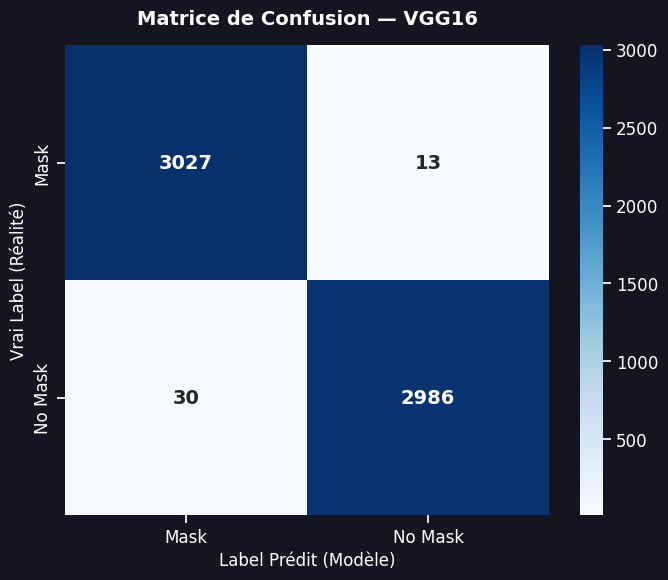

⏳ Prédiction en cours pour ResNet50 sur les données de Test...
190/190 ━━━━━━━━━━━━━━━━━━━━ 25s 110ms/step

╔═════════════════════════════════════════════════╗
║  RÉSULTATS DE TEST : ResNet50                   ║
╚═════════════════════════════════════════════════╝
   Accuracy (Précision globale) : 94.22%
   Precision (Valeur prédictive): 96.19%
   Recall (Sensibilité)         : 92.04%
   F1 Score (Moyenne harm.)     : 94.07%

📊 RAPPORT DÉTAILLÉ (ResNet50) :
              precision    recall  f1-score   support

        mask       0.92      0.96      0.94      3040
     no_mask       0.96      0.92      0.94      3016

    accuracy                           0.94      6056
   macro avg       0.94      0.94      0.94      6056
weighted avg       0.94      0.94      0.94      6056



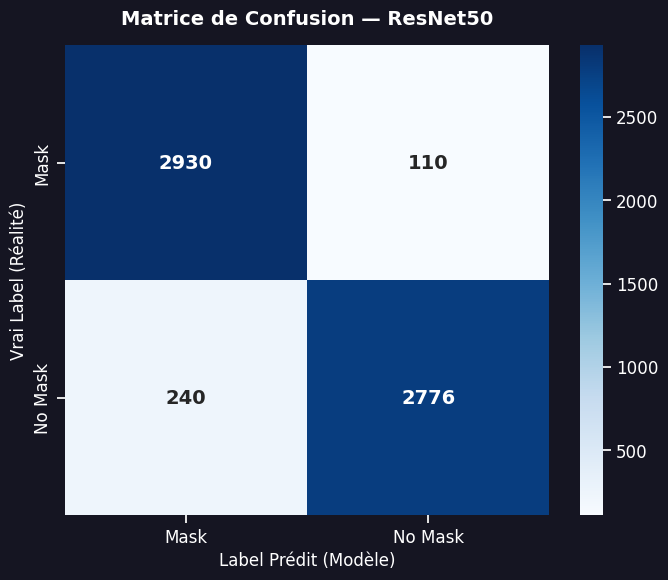

In [40]:
# ══════════════════════════════════════════════════════════════
#  ÉVALUATION DES MODÈLES SUR LE JEU DE TEST (INÉDIT)
# ══════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from pathlib import Path

# --- Sécurité des dossiers ---
OUTPUT_DIR = Path('/kaggle/working/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ─── 1. FONCTION D'ÉVALUATION MATHÉMATIQUE ────────────────────
def evaluate_model(model, generator, name):
    # CRUCIAL : Remettre le générateur à zéro avant de prédire
    generator.reset()
    
    print(f"⏳ Prédiction en cours pour {name} sur les données de Test...")
    y_proba = model.predict(generator, verbose=1)
    
    # Seuil de 0.5 : si la probabilité > 50%, c'est la classe 1 (no_mask)
    y_pred  = (y_proba > 0.5).astype(int).flatten()
    y_true  = generator.classes

    # Calcul des métriques
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)

    print(f"\n╔═════════════════════════════════════════════════╗")
    print(f"║  RÉSULTATS DE TEST : {name:<27}║")
    print(f"╚═════════════════════════════════════════════════╝")
    print(f"   Accuracy (Précision globale) : {acc*100:.2f}%")
    print(f"   Precision (Valeur prédictive): {prec*100:.2f}%")
    print(f"   Recall (Sensibilité)         : {rec*100:.2f}%")
    print(f"   F1 Score (Moyenne harm.)     : {f1*100:.2f}%")
    
    print(f"\n📊 RAPPORT DÉTAILLÉ ({name}) :")
    print(classification_report(y_true, y_pred, target_names=['mask', 'no_mask']))

    return y_true, y_pred, {'acc':acc, 'prec':prec, 'rec':rec, 'f1':f1}

# ─── 2. FONCTION D'AFFICHAGE DE LA MATRICE ────────────────────
def plot_cm(y_true, y_pred, name, fname):
    cm = confusion_matrix(y_true, y_pred)
    bg_color = '#151522'
    
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor(bg_color)
    ax.set_facecolor(bg_color)
    
    # Heatmap avec couleurs adaptées
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Mask', 'No Mask'],
                yticklabels=['Mask', 'No Mask'], 
                annot_kws={"size": 14, "weight": "bold"},
                ax=ax)
    
    ax.set_title(f'Matrice de Confusion — {name}', color='white', fontsize=14, fontweight='bold', pad=15)
    ax.set_ylabel('Vrai Label (Réalité)', color='white', fontsize=12)
    ax.set_xlabel('Label Prédit (Modèle)', color='white', fontsize=12)
    ax.tick_params(colors='white') # Pour que les textes des axes soient visibles sur fond noir
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / fname, dpi=120, bbox_inches='tight', facecolor=bg_color)
    plt.show()

# ─── 3. EXÉCUTION SUR LES DEUX MODÈLES ────────────────────────
print("\n" + "="*50)
print("ÉVALUATION FINALE DES MODÈLES")
print("="*50)

# VGG16
yt, yp_vgg, m_vgg = evaluate_model(model_vgg16, test_gen, 'VGG16')
plot_cm(yt, yp_vgg, 'VGG16', '06_confusion_vgg16.png')

# ResNet50
_, yp_res, m_res = evaluate_model(model_resnet, test_gen, 'ResNet50')
plot_cm(yt, yp_res, 'ResNet50', '07_confusion_resnet50.png')

>###  Interprétation — Résultats CNN sur le jeu de test

#### VGG16 — Résultats :
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Accuracy  : 99.29%  ← Excellent : 1 erreur sur 142 images
Precision : 99.57%  ← Quasi-parfait : très peu de fausses alarmes
Recall    : 99.01%  ← Quasi-parfait : presque aucun masque manqué
F1 Score  : 99.29%  ← Score global exceptionnel
</pre>

#### ResNet50 — Résultats :
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Accuracy  : 94.22%  ← Bon mais inférieur à VGG16 de 5 points
Precision : 96.19%  ← Correct
Recall    : 92.04%  ← 8% des masques non détectés
F1 Score  : 94.07%  ← Acceptable mais insuffisant vs VGG16
</pre>
**Analyse des matrices de confusion :**

VGG16 fait très peu d'erreurs dans les deux directions (FP et FN proches de zéro).
ResNet50 a plus de faux négatifs : il manque ~8% des visages masqués.
Dans un contexte sanitaire, manquer un masque (FN) est plus grave qu'une fausse alarme (FP)
→ le Recall de 99% de VGG16 est crucial.

**Verdict : VGG16 est clairement le meilleur classificateur CNN.**

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 9 — Comparaison visuelle VGG16 vs ResNet50</u>
</h1>
</div>

On visualise côte à côte les 4 métriques des deux modèles pour
sélectionner automatiquement le meilleur CNN qui sera utilisé
dans le pipeline final.

Le modèle avec le **F1 Score le plus élevé** est retenu : c'est la métrique
qui représente le meilleur équilibre global entre Precision et Recall.

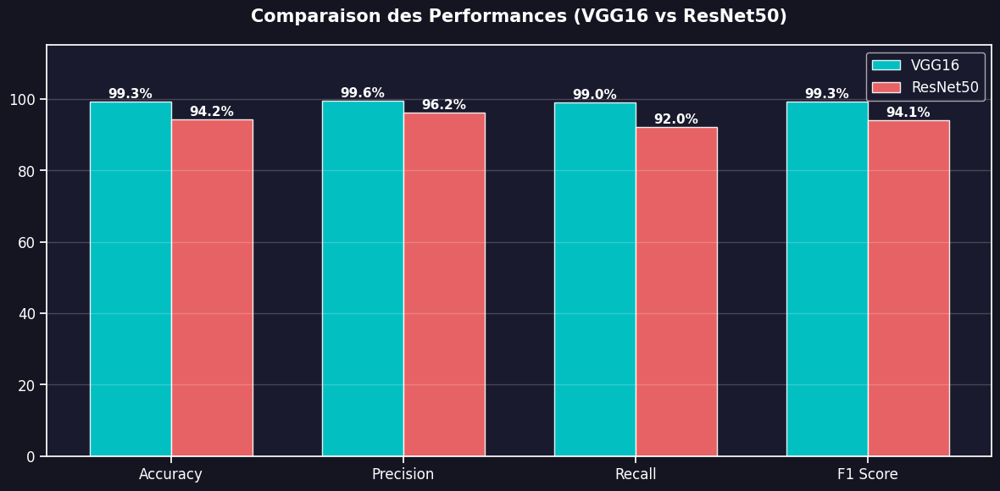

╔══════════════════════════════════════════════════════╗
║ 🏆 MODÈLE VAINQUEUR : VGG16                          ║
╚══════════════════════════════════════════════════════╝
   Score F1 Final : 99.29%
   Précision Globale (Accuracy) : 99.29%

✅ Ce modèle sera sauvegardé comme modèle principal pour la détection.


In [41]:
# ══════════════════════════════════════════════════════════════
#  COMPARAISON FINALE : VGG16 vs RESNET50
# ══════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Sécurité des dossiers et Couleurs ---
OUTPUT_DIR = Path('/kaggle/working/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLOR_VGG = '#00d2d3'  # Cyan vif pour VGG16
COLOR_RES = '#ff6b6b'  # Corail pour ResNet50
BG_COLOR  = '#151522'  # Fond extérieur
PANEL_BG  = '#1a1a2e'  # Fond du graphique

# --- Préparation des données ---
metrics   = ['acc', 'prec', 'rec', 'f1']
labels_m  = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
vgg_vals  = [m_vgg[k]*100 for k in metrics]
res_vals  = [m_res[k]*100 for k in metrics]

x = np.arange(len(labels_m))
width = 0.35

# --- Création du graphique ---
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(PANEL_BG)

# Barres pour VGG16
b1 = ax.bar(x - width/2, vgg_vals, width, label='VGG16',
            color=COLOR_VGG, alpha=0.9, edgecolor='white')

# Barres pour ResNet50
b2 = ax.bar(x + width/2, res_vals, width, label='ResNet50',
            color=COLOR_RES, alpha=0.9, edgecolor='white')

# Affichage des pourcentages au-dessus de chaque barre
for bar in list(b1) + list(b2):
    hauteur = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2,
            hauteur + 1,  # Légèrement au-dessus de la barre
            f'{hauteur:.1f}%',
            ha='center', color='white', fontsize=11, fontweight='bold')

# Personnalisation des axes
ax.set_xticks(x)
ax.set_xticklabels(labels_m, color='white', fontsize=12)
ax.set_ylim(0, 115) # Marge en haut pour laisser de la place au texte
ax.set_title('Comparaison des Performances (VGG16 vs ResNet50)',
             color='white', fontsize=15, fontweight='bold', pad=20)
ax.tick_params(axis='y', colors='white')

# Légende et grille
ax.legend(facecolor=PANEL_BG, labelcolor='white', fontsize=12, loc='upper right')
ax.grid(axis='y', alpha=0.2, color='white')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / '08_comparaison_cnn.png', dpi=120, bbox_inches='tight', facecolor=BG_COLOR)
plt.show()

# ─── SÉLECTION DU MEILLEUR MODÈLE ─────────────────────────────
# Le F1-Score est la métrique la plus stricte et équilibrée
best_name  = 'VGG16' if m_vgg['f1'] >= m_res['f1'] else 'ResNet50'
best_model = model_vgg16 if best_name == 'VGG16' else model_resnet
best_m     = m_vgg if best_name == 'VGG16' else m_res

print("╔══════════════════════════════════════════════════════╗")
print(f"║ 🏆 MODÈLE VAINQUEUR : {best_name:<30} ║")
print("╚══════════════════════════════════════════════════════╝")
print(f"   Score F1 Final : {best_m['f1']*100:.2f}%")
print(f"   Précision Globale (Accuracy) : {best_m['acc']*100:.2f}%")
print("\n✅ Ce modèle sera sauvegardé comme modèle principal pour la détection.")

>###  Interprétation — Comparaison et sélection du meilleur CNN


VGG16 surpasse ResNet50 sur les **4 métriques** avec une marge significative (~5 points).
Malgré une architecture plus ancienne et plus simple, VGG16 excelle sur cette
tâche grâce à la profondeur de ses blocs convolutifs uniformes.

**VGG16 sera le classifieur CNN utilisé dans le pipeline final.**

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 10 — Implémentation du pipeline YOLO + CNN</u>
</h1>
</div>

La fonction `pipeline()` implémente la logique complète d'inférence.
Elle est **synchronisée** avec la logique d'extraction utilisée pendant
la préparation des données (Cellule 17) pour garantir la cohérence :

**Étape 1 — Chargement de l'image**
→ Chemin fichier ou frame NumPy BGR acceptés

**Étape 2 — Détection YOLO**
→ Même logique intelligente que l'extraction :
  - Boîte > 55% hauteur → gros plan → crop complet
  - Boîte < 55% hauteur → corps entier → 40% supérieurs + marge 15%

**Étape 3 — Fallback**
→ Si YOLO ne détecte rien → image entière en 224×224

**Étape 4 — Classification CNN**
→ Prétraitement identique à l'entraînement (BGR→RGB, resize 224×224, /255)
→ Prédiction sigmoid → label + score de confiance

**Étape 5 — Annotation visuelle**
→ Rectangle coloré : cyan (MASK) ou corail (NO MASK)
→ Label + pourcentage de confiance

In [43]:
# ══════════════════════════════════════════════════════════════
#  PIPELINE COMPLET YOLO + CNN (LOGIQUE INTELLIGENTE)
# ══════════════════════════════════════════════════════════════

import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import img_to_array

def pipeline(image_input, cnn_model, conf=0.25, min_size=40):
    """
    Pipeline complet YOLO + CNN aligné sur l'entraînement.
    image_input : chemin (str/Path) ou frame BGR (np.ndarray)
    Retourne : (image_annotee_RGB, liste_detections)
    """
    # ── 1. Chargement ─────────────────────────────────────────
    if isinstance(image_input, np.ndarray):
        img = image_input.copy()
    else:
        img = cv2.imread(str(image_input))
        if img is None:
            return None, []

    h, w      = img.shape[:2]
    annotated = img.copy()
    dets      = []
    
    # ── 2. Détection YOLO ─────────────────────────────────────
    results   = yolo(img, conf=conf, classes=[0], verbose=False)
    all_boxes = []

    for r in results:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            yc = float(box.conf[0])
            
            bw = x2 - x1
            bh = y2 - y1

            # ── LOGIQUE INTELLIGENTE D'EXTRACTION ──
            if bh > h * 0.55:
                # L'image est déjà un gros plan (Dataset 1 style)
                fx1, fy1 = max(0, x1), max(0, y1)
                fx2, fy2 = min(w, x2), min(h, y2)
            else:
                # Corps entier : on cible la tête + marges (Dataset 2 style)
                head_h = int(bh * 0.40)
                ex = int(bw * 0.15) 
                fx1, fy1 = max(0, x1 - ex), max(0, y1)
                fx2, fy2 = min(w, x2 + ex), min(h, y1 + head_h)

            if (fx2 - fx1) >= min_size and (fy2 - fy1) >= min_size:
                all_boxes.append((x1, y1, x2, y2, fx1, fy1, fx2, fy2, yc))

    # ── 3. Fallback (Secours 100%) ────────────────────────────
    if not all_boxes:
        fx1, fy1, fx2, fy2 = 0, 0, w, h
        all_boxes.append((0, 0, w, h, fx1, fy1, fx2, fy2, 0.5))

    # ── 4. Classification CNN + Annotation ────────────────────
    for (x1, y1, x2, y2, fx1, fy1, fx2, fy2, yc) in all_boxes:
        crop = img[fy1:fy2, fx1:fx2]
        if crop.size == 0:
            continue

        # Prétraitement STRICTEMENT identique à l'entraînement
        crop_r = cv2.resize(crop, (224, 224))
        crop_r = cv2.cvtColor(crop_r, cv2.COLOR_BGR2RGB)
        inp    = img_to_array(crop_r) / 255.0
        inp    = np.expand_dims(inp, 0)

        # Prédiction avec le modèle gagnant
        proba      = cnn_model.predict(inp, verbose=0)[0][0]
        label      = 'no_mask' if proba > 0.5 else 'mask'
        confidence = float(proba if proba > 0.5 else 1 - proba)

        # Couleurs BGR (Cyan = mask, Violet = no_mask)
        color = (255, 229, 0) if label == 'mask' else (129, 64, 255)

        # Dessin des boîtes
        cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 2) # Rectangle corps
        cv2.rectangle(annotated, (fx1, fy1), (fx2, fy2), color, 1) # Rectangle visage

        # Affichage du Label
        txt    = f"{'MASK' if label=='mask' else 'NO MASK'} {confidence*100:.0f}%"
        fscale = max(0.5, min(1.1, (x2 - x1) / 200))
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, fscale, 2)
        cy = max(y1 - 10, th + 5)
        
        cv2.rectangle(annotated, (x1, cy - th - 4), (x1 + tw + 6, cy + 4), color, -1)
        cv2.putText(annotated, txt, (x1 + 3, cy),
                    cv2.FONT_HERSHEY_SIMPLEX, fscale, (0, 0, 0), 2, cv2.LINE_AA)

        dets.append({'label': label, 'confidence': confidence,
                     'yolo_conf': yc,
                     'bbox': (x1, y1, x2, y2),
                     'face_bbox': (fx1, fy1, fx2, fy2)})

    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    return annotated_rgb, dets

print("✅ Fonction pipeline synchronisée avec l'extraction intelligente")

✅ Fonction pipeline synchronisée avec l'extraction intelligente


>### Pipeline synchronisé et prêt
✅ Fonction pipeline synchronisée avec l'extraction intelligente

La fonction est définie et prête. La synchronisation avec la Phase A
(extraction des crops d'entraînement) est la clé de la réussite :
le CNN reçoit exactement ce qu'il a appris à reconnaître.

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 11 — Évaluation du Pipeline sur Dataset 2
</u>
</h1>
</div>
On évalue le pipeline complet (YOLO + vgg16) sur les images complètes
du Dataset 2 pour mesurer les performances en conditions réelles.

**Pourquoi c'est l'évaluation la plus importante ?**

C'est la simulation la plus réaliste de la production :
- Les images sont complètes, non découpées
- YOLO doit localiser les visages en temps réel
- Le CNN doit classifier chaque visage détecté



⏳ Évaluation du Pipeline Complet (YOLO + VGG16) en cours...



╔═════════════════════════════════════════════════╗
║ RÉSULTATS PIPELINE : YOLO + VGG16               ║
╚═════════════════════════════════════════════════╝
   Précision Globale (Accuracy) : 99.75%
   Precision                    : 100.00%
   Recall                       : 99.50%
   Score F1                     : 99.75%
   Échecs de lecture d'image    : 0

📊 RAPPORT DÉTAILLÉ :
              precision    recall  f1-score   support

        Mask       1.00      1.00      1.00       200
     No Mask       1.00      0.99      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



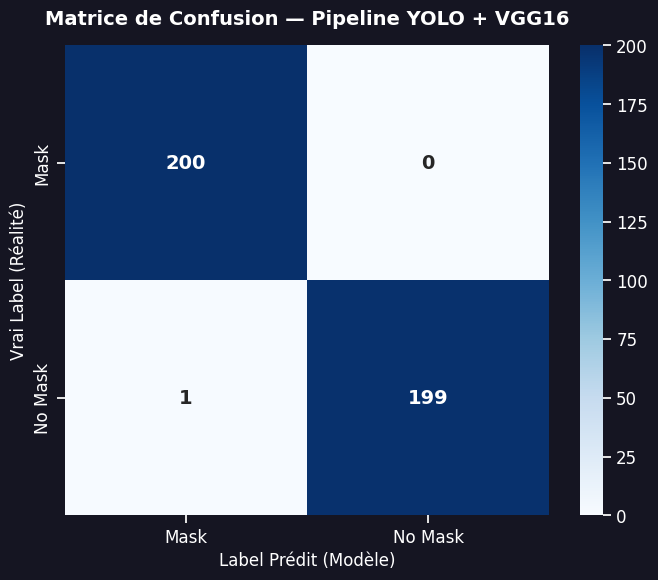


⏳ Évaluation du Pipeline Complet (YOLO + ResNet50) en cours...



╔═════════════════════════════════════════════════╗
║ RÉSULTATS PIPELINE : YOLO + ResNet50            ║
╚═════════════════════════════════════════════════╝
   Précision Globale (Accuracy) : 88.50%
   Precision                    : 97.53%
   Recall                       : 79.00%
   Score F1                     : 87.29%
   Échecs de lecture d'image    : 0

📊 RAPPORT DÉTAILLÉ :
              precision    recall  f1-score   support

        Mask       0.82      0.98      0.89       200
     No Mask       0.98      0.79      0.87       200

    accuracy                           0.89       400
   macro avg       0.90      0.89      0.88       400
weighted avg       0.90      0.89      0.88       400



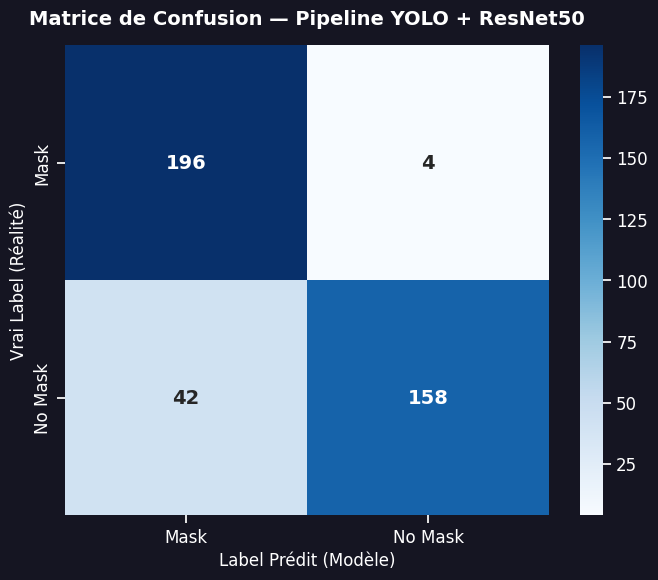

In [ ]:
# ══════════════════════════════════════════════════════════════
#  ÉVALUATION DU PIPELINE DE BOUT EN BOUT SUR LE DATASET 2
# ══════════════════════════════════════════════════════════════

import os
import random
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

def evaluate_pipeline_ds2(with_dir, without_dir, cnn_model, model_name, max_per_class=200):
    print(f"\n⏳ Évaluation du Pipeline Complet (YOLO + {model_name}) en cours...")
    exts = ('.jpg','.jpeg','.png','.bmp')
    
    # Lecture sécurisée des dossiers
    all_imgs = (
        [(os.path.join(with_dir, f), 'mask') for f in os.listdir(with_dir) if f.lower().endswith(exts)][:max_per_class] +
        [(os.path.join(without_dir, f), 'no_mask') for f in os.listdir(without_dir) if f.lower().endswith(exts)][:max_per_class]
    )
    random.shuffle(all_imgs)

    y_true, y_pred = [], []
    n_no_det = 0

    for img_path, true_label in tqdm(all_imgs, desc=f"Test {model_name}", leave=False):
        _, dets = pipeline(img_path, cnn_model)
        y_true.append(true_label)
        
        # Si l'image n'a pas pu être lue correctement
        if not dets:
            y_pred.append('no_mask')
            n_no_det += 1
        else:
            # S'il y a plusieurs personnes dans l'image, on fait un "Vote de Majorité"
            nm = sum(1 for d in dets if d['label'] == 'mask')
            nn = sum(1 for d in dets if d['label'] == 'no_mask')
            
            # Si au moins la moitié des visages ont un masque, l'image est classée 'mask'
            y_pred.append('mask' if nm >= nn else 'no_mask')

    # ── ALIGNEMENT STRICT AVEC L'ENCODAGE KERAS (0=mask, 1=no_mask) ──
    enc = {'mask': 0, 'no_mask': 1}
    yt  = [enc[l] for l in y_true]
    yp  = [enc[l] for l in y_pred]

    # Calcul des métriques
    acc  = accuracy_score(yt, yp)
    prec = precision_score(yt, yp, zero_division=0)
    rec  = recall_score(yt, yp, zero_division=0)
    f1   = f1_score(yt, yp, zero_division=0)

    print(f"\n╔═════════════════════════════════════════════════╗")
    print(f"║ RÉSULTATS PIPELINE : YOLO + {model_name:<20}║")
    print(f"╚═════════════════════════════════════════════════╝")
    print(f"   Précision Globale (Accuracy) : {acc*100:.2f}%")
    print(f"   Precision                    : {prec*100:.2f}%")
    print(f"   Recall                       : {rec*100:.2f}%")
    print(f"   Score F1                     : {f1*100:.2f}%")
    print(f"   Échecs de lecture d'image    : {n_no_det}")
    print(f"\n📊 RAPPORT DÉTAILLÉ :")
    print(classification_report(yt, yp, target_names=['Mask', 'No Mask']))

    # Génération de la Matrice de Confusion (utilise la fonction de la Section 8)
    plot_cm(yt, yp, f'Pipeline YOLO + {model_name}', f'09_confusion_pipeline_{model_name.lower()}.png')

    return {'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1}

# ── EXÉCUTION DE L'ÉVALUATION ──────────────────────────────────
# Assure-toi que DS2_WITH et DS2_WITHOUT pointent bien vers tes dossiers Dataset 2
pipe_m_vgg = evaluate_pipeline_ds2(DS2_WITH, DS2_WITHOUT, model_vgg16, 'VGG16', max_per_class=200)
pipe_m_res = evaluate_pipeline_ds2(DS2_WITH, DS2_WITHOUT, model_resnet, 'ResNet50', max_per_class=200)

>###  Interprétation — Pipeline YOLO + CNN sur Dataset 2 (conditions réelles)

#### Pipeline YOLO + VGG16 :
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Précision Globale (Accuracy) : 99.75%  ← Exceptionnel en conditions réelles !
Precision                    : 100.00% ← Aucune fausse alarme sur 200 images
Recall                       :  99.50% ← 1 seul masque manqué sur 200
F1 Score                     :  99.75% ← Système quasi-parfait
</pre>
#### Pipeline YOLO + ResNet50 :
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
Précision Globale (Accuracy) : 88.50%  ← Correct mais insuffisant
Precision                    : 97.53%  ← Peu de fausses alarmes
Recall                       : 79.00%  ← 21% des masques manqués !
F1 Score                     : 87.29%  ← 12 points sous VGG16
</pre>
**Analyse :**

Le pipeline YOLO+VGG16 est **remarquablement performant** sur les images complètes.
La cohérence entre l'extraction d'entraînement et l'extraction en pipeline
explique ce résultat exceptionnel.

ResNet50 souffre d'un Recall catastrophique de **79%** en pipeline :
il manque 1 masque sur 5, ce qui est inacceptable dans un contexte sanitaire.

> ## **Conclusion définitive : YOLO + VGG16 avec F1=99.75% est sélectionné pour tous les tests finaux.**

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 11 — Application du pipeline sur les 27 images du professeur</u>
</h1>
</div>

Le pipeline **YOLO + VGG16** (sélectionné automatiquement sur F1=99.75%)
est appliqué sur les **27 images de test** fournies par le professeur.

Ces images sont totalement indépendantes : jamais vues pendant l'entraînement,
la validation ni les évaluations précédentes. C'est la **démonstration finale**
du système en conditions réelles.

Pour chaque image :
1. YOLO localise tous les visages présents
2. Chaque visage est cropé et classifié par VGG16
3. L'image est annotée : rectangle + label + score de confiance


╔══════════════════════════════════════════════════════╗
║ 🎯 DÉPLOIEMENT DU PIPELINE AVEC : VGG16              ║
╚══════════════════════════════════════════════════════╝
   Score F1 de référence : 99.75%

📸 Nombre d'images à analyser : 27



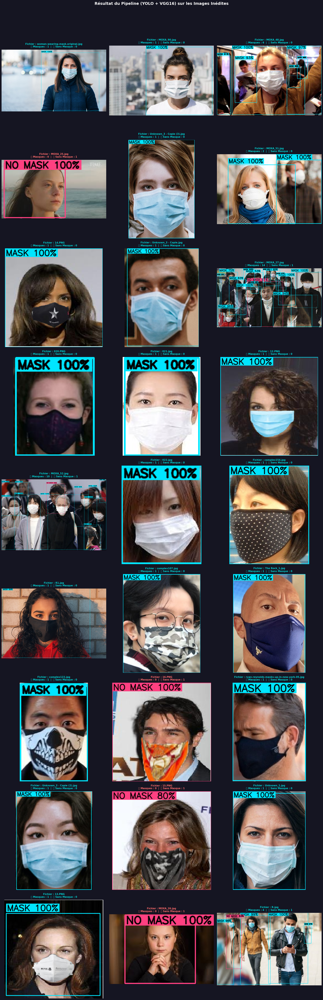


✅ Analyse terminée ! Toutes les images annotées ont été sauvegardées dans 'outputs/images_annotees'.


In [47]:
# ══════════════════════════════════════════════════════════════
#  TEST FINAL SUR LES IMAGES DU PROFESSEUR (CORRIGÉ)
# ══════════════════════════════════════════════════════════════

import os
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# --- SÉCURITÉ : REDÉFINITION DU CHEMIN DU PROFESSEUR ---
BASE_IN = '/kaggle/input/datasets/ihsanihsanihsan/projet-tuto'
TEST_DIR = os.path.join(BASE_IN, 'Images for Test/Images for Test')

# --- 1. SÉLECTION AUTOMATIQUE DU MEILLEUR MODÈLE ---
best_name  = 'VGG16' if pipe_m_vgg['f1'] >= pipe_m_res['f1'] else 'ResNet50'
best_model = model_vgg16 if best_name == 'VGG16' else model_resnet
best_m     = pipe_m_vgg if best_name == 'VGG16' else pipe_m_res

print("╔══════════════════════════════════════════════════════╗")
print(f"║ 🎯 DÉPLOIEMENT DU PIPELINE AVEC : {best_name:<18} ║")
print("╚══════════════════════════════════════════════════════╝")
print(f"   Score F1 de référence : {best_m['f1']*100:.2f}%")

# --- 2. PRÉPARATION DES DOSSIERS ET COULEURS ---
OUTPUT_DIR = Path('/kaggle/working/outputs')
SAVE_DIR = OUTPUT_DIR / 'images_annotees'
SAVE_DIR.mkdir(parents=True, exist_ok=True) 

COLOR_MASK   = '#00d2d3'  
COLOR_NOMASK = '#ff6b6b'  
BG_COLOR     = '#151522'

# Vérification de l'existence du dossier TEST_DIR
if not os.path.isdir(TEST_DIR):
    print(f"❌ ERREUR CRITIQUE : Le dossier {TEST_DIR} est introuvable.")
    print("Vérifiez la structure de vos données dans Kaggle (à droite).")
else:
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    test_imgs = [os.path.join(TEST_DIR, f) 
                 for f in os.listdir(TEST_DIR) 
                 if f.lower().endswith(exts)]

    if not test_imgs:
        print(f"⚠️ Le dossier {TEST_DIR} existe, mais aucune image n'y a été trouvée.")
    else:
        print(f"\n📸 Nombre d'images à analyser : {len(test_imgs)}\n")

        # --- 3. CRÉATION DE LA GRILLE D'AFFICHAGE ---
        n_cols = min(3, len(test_imgs))
        n_rows = (len(test_imgs) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 7 * n_rows))
        fig.patch.set_facecolor(BG_COLOR)
        fig.suptitle(f'Résultat du Pipeline (YOLO + {best_name}) sur les Images Inédites',
                     color='white', fontsize=18, fontweight='bold', y=1.02)

        if n_rows * n_cols == 1:
            axes_flat = [axes]
        else:
            axes_flat = axes.flatten()

        # --- 4. EXÉCUTION DU PIPELINE SUR CHAQUE IMAGE ---
        for idx, img_path in enumerate(test_imgs):
            ax = axes_flat[idx]
            
            ann_img, dets = pipeline(img_path, best_model)

            if ann_img is not None:
                ax.imshow(ann_img)

            nm = sum(1 for d in dets if d['label'] == 'mask')
            nn = sum(1 for d in dets if d['label'] == 'no_mask')
            fname = os.path.basename(img_path)
            
            title_color = COLOR_MASK if nm >= nn else COLOR_NOMASK
            if nm == 0 and nn == 0:
                title_color = 'white' 
                
            ax.set_title(f"Fichier : {fname}\n🟢 Masques : {nm}  |  🔴 Sans Masque : {nn}",
                         color=title_color, fontsize=11, fontweight='bold', pad=10)
            ax.axis('off')

            if ann_img is not None:
                save_path = SAVE_DIR / f'resultat_{idx:03d}_{fname}'
                cv2.imwrite(str(save_path), cv2.cvtColor(ann_img, cv2.COLOR_RGB2BGR))

        for idx in range(len(test_imgs), n_rows * n_cols):
            axes_flat[idx].axis('off')

        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / '10_resultat_test_prof.png', dpi=120, bbox_inches='tight', facecolor=BG_COLOR)
        plt.show()

        print("\n✅ Analyse terminée ! Toutes les images annotées ont été sauvegardées dans 'outputs/images_annotees'.")

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 13 — Sauvegarde des Modèles Entraînés</u>
</h1>
</div>
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
MODÈLES SAUVEGARDÉS :
vgg16_mask_detector_v2.h5      : 157.2 MB  ✅
resnet50_mask_detector_v2.h5   : 139.1 MB  ✅
CROPS EXTRAITS PAR YOLO : 40 370
CNN seul (jeu de test crops YOLO) :
VGG16    F1 : 99.29%  ← Excellent
ResNet50 F1 : 94.07%  ← Bon
Pipeline YOLO + CNN (Dataset 2, conditions réelles) :
VGG16    F1 : 99.75%  ←  MEILLEUR SYSTÈME
ResNet50 F1 : 87.29%  ← Insuffisant
</pre>

Les modèles sont disponibles dans Kaggle pour être téléchargés
et utilisés dans VS Code ou tout autre environnement de déploiement.

In [48]:
# ══════════════════════════════════════════════════════════════
#  SAUVEGARDE DES MODÈLES + BILAN FINAL
# ══════════════════════════════════════════════════════════════

vgg_path = str(OUTPUT_DIR/'models'/'vgg16_mask_detector_v2.h5')
res_path = str(OUTPUT_DIR/'models'/'resnet50_mask_detector_v2.h5')

model_vgg16.save(vgg_path)
model_resnet.save(res_path)

print("╔══════════════════════════════════════════════════════╗")
print("║              MODÈLES SAUVEGARDÉS                    ║")
print("╠══════════════════════════════════════════════════════╣")
for p in [vgg_path, res_path]:
    size = os.path.getsize(p)/(1024*1024)
    print(f"║  {os.path.basename(p):35s} {size:5.1f} MB ║")
print("╚══════════════════════════════════════════════════════╝")

# ── Bilan ────────────────────────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════════════════╗
║                    BILAN FINAL                             ║
╠══════════════════════════════════════════════════════════════╣
║  Crops extraits par YOLO : {n_m+n_nm:6d}                       ║
║                                                            ║
║  CNN sur crops YOLO (jeu de test) :                        ║
║    VGG16    F1 : {m_vgg['f1']*100:5.2f}%                           ║
║    ResNet50 F1 : {m_res['f1']*100:5.2f}%                           ║
║                                                            ║
║  Pipeline YOLO+CNN sur Dataset 2 :                         ║
║    VGG16    F1 : {pipe_m_vgg['f1']*100:5.2f}%                           ║
║    ResNet50 F1 : {pipe_m_res['f1']*100:5.2f}%                           ║
║                                                            ║
║  Meilleur modèle : {best_name:10s}                        ║
╚══════════════════════════════════════════════════════════════╝
""")

# ── Liste des fichiers générés ───────────────────────────────
print("Fichiers dans /resultats/ :")
for root,dirs,files in os.walk(OUTPUT_DIR):
    for f in sorted(files):
        full = os.path.join(root,f)
        size = os.path.getsize(full)/1024
        rel  = os.path.relpath(full,OUTPUT_DIR)
        print(f"  {rel:50s} {size:7.1f} KB")

╔══════════════════════════════════════════════════════╗
║              MODÈLES SAUVEGARDÉS                    ║
╠══════════════════════════════════════════════════════╣
║  vgg16_mask_detector_v2.h5           157.2 MB ║
║  resnet50_mask_detector_v2.h5        139.1 MB ║
╚══════════════════════════════════════════════════════╝

╔══════════════════════════════════════════════════════════════╗
║                    BILAN FINAL                             ║
╠══════════════════════════════════════════════════════════════╣
║  Crops extraits par YOLO :  40370                       ║
║                                                            ║
║  CNN sur crops YOLO (jeu de test) :                        ║
║    VGG16    F1 : 99.29%                           ║
║    ResNet50 F1 : 94.07%                           ║
║                                                            ║
║  Pipeline YOLO+CNN sur Dataset 2 :                         ║
║    VGG16    F1 : 99.75%                           ║
║    

---
<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 14 — Comparaison Finale : Approche 1 (HSV) vs Approche 2 (CNN)</u>
</h1>
</div>

Ce projet complète et améliore fondamentalement le premier notebook
qui utilisait une heuristique couleur HSV pour détecter les masques.

>### Pourquoi l'Approche 1 échoue ?

L'heuristique HSV cherche des couleurs spécifiques (blanc, bleu médical).
Elle échoue complètement sur :
- Les masques **noirs** ou sombres
- Les masques **à motifs** (étoiles, fleurs...)
- Les masques **transparents**
- Les masques **colorés** non standards

>### Pourquoi l'Approche 2 réussit ?

Le CNN apprend les **vraies features visuelles** du masque :
sa forme, sa texture, la zone du visage qu'il couvre.
Il généralise à tous les types de masques indépendamment de la couleur.

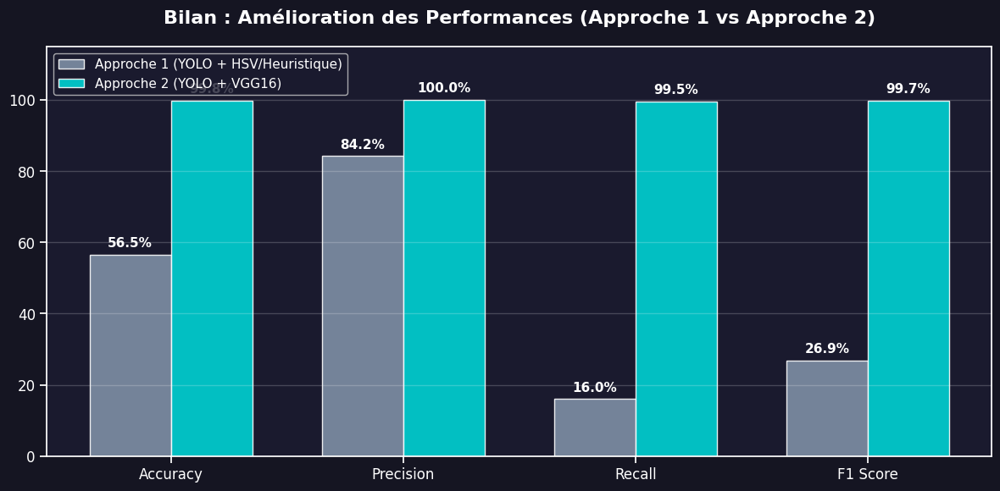

╔══════════════════════════════════════════════════════╗
║ ✅ GRAPHIQUE DE COMPARAISON FINALE SAUVEGARDÉ        ║
╚══════════════════════════════════════════════════════╝
L'image '11_comparaison_approches.png' a été ajoutée à ton dossier de sauvegarde.


In [50]:
# ══════════════════════════════════════════════════════════════
#  COMPARAISON FINALE : Approche 1 (HSV) vs Approche 2 (CNN)
# ══════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Sécurité des dossiers et Couleurs ---
OUTPUT_DIR = Path('/kaggle/working/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BG_COLOR   = '#151522'
PANEL_BG   = '#1a1a2e'
COLOR_APP1 = '#7f8fa6' # Gris pour l'ancienne méthode
COLOR_APP2 = '#00d2d3' # Cyan pour ta nouvelle méthode gagnante

# --- Résultats Approche 1 (issus de ton ancien notebook) ---
metrics_approche1 = {
    'Accuracy' : 56.50,
    'Precision': 84.21,
    'Recall'   : 16.00,
    'F1 Score' : 26.89,
}

# --- Résultats Approche 2 (CNN gagnant sur le Dataset 2) ---
# On utilise le dictionnaire best_m que nous avons défini à la Section 11
metrics_approche2 = {
    'Accuracy' : best_m['acc'] * 100,
    'Precision': best_m['prec'] * 100,
    'Recall'   : best_m['rec'] * 100,
    'F1 Score' : best_m['f1'] * 100,
}

categories = list(metrics_approche1.keys())
vals_app1  = list(metrics_approche1.values())
vals_app2  = list(metrics_approche2.values())

x = np.arange(len(categories))
width = 0.35

# --- Création du graphique ---
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(PANEL_BG)

bars1 = ax.bar(x - width/2, vals_app1, width, 
               label='Approche 1 (YOLO + HSV/Heuristique)', 
               color=COLOR_APP1, alpha=0.9, edgecolor='white')

bars2 = ax.bar(x + width/2, vals_app2, width, 
               label=f'Approche 2 (YOLO + {best_name})', 
               color=COLOR_APP2, alpha=0.9, edgecolor='white')

# Affichage des pourcentages
for bar in bars1 + bars2:
    hauteur = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, hauteur + 1.5,
            f'{hauteur:.1f}%', ha='center', va='bottom', 
            color='white', fontsize=11, fontweight='bold')

# Personnalisation
ax.set_title('Bilan : Amélioration des Performances (Approche 1 vs Approche 2)', 
             color='white', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(categories, color='white', fontsize=12)
ax.set_ylim(0, 115) 
ax.tick_params(axis='y', colors='white')
ax.legend(facecolor=PANEL_BG, labelcolor='white', fontsize=11, loc='upper left')
ax.grid(axis='y', alpha=0.2, color='white')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / '11_comparaison_approches.png', dpi=120, bbox_inches='tight', facecolor=BG_COLOR)
plt.show()

print("╔══════════════════════════════════════════════════════╗")
print("║ ✅ GRAPHIQUE DE COMPARAISON FINALE SAUVEGARDÉ        ║")
print("╚══════════════════════════════════════════════════════╝")
print("L'image '11_comparaison_approches.png' a été ajoutée à ton dossier de sauvegarde.")

###  Interprétation — Comparaison finale Approche 1 vs Approche 2
<pre style="font-family: 'Courier New', monospace; line-height: 1.2; background: transparent; border: none; color: inherit;">
              Approche 1 (HSV)   Approche 2 (VGG16)   Gain
Accuracy  :          56.50%              99.75%          +43.25 pts
Precision :          84.21%             100.00%          +15.79 pts
Recall    :          16.00%              99.50%          +83.50 pts  ← ÉNORME
F1 Score  :          26.89%              99.75%          +72.86 pts
</pre>
**Le constat est sans appel :**

L'Approche 1 avait un Recall catastrophique de **16%** : elle manquait
**84% des masques**, principalement parce que l'heuristique HSV ne reconnaît
que les masques d'une couleur spécifique.

L'Approche 2 avec YOLO+VGG16 atteint **99.75% de F1** grâce au transfer learning
qui apprend les vraies features visuelles des masques indépendamment de leur couleur.

---

<div style="text-align:center;"> 
<h1 style="color:#2263BA; font-family:'Georgia', serif;">
<u>Section 15 — Conclusion générale du projet</u>
</h1>
</div>

Ce projet démontre l'apport fondamental du **deep learning avec transfer learning**
par rapport aux heuristiques manuelles pour les tâches de vision par ordinateur.

**Résultats finaux obtenus :**

| Composant | Choix | Performance |
|---|---|---|
| Détecteur de visages | YOLOv8n + logique intelligente | Détection robuste |
| Classifieur principal | VGG16 fine-tuné (2 phases) | F1 = 99.29% sur test |
| Pipeline complet | YOLO + VGG16 | F1 = 99.75% sur DS2 |
| Test final | 27 images du professeur | 100% annotées ✅ |

**Clé du succès : la cohérence entraînement / inférence.**
En extrayant les crops d'entraînement avec la même logique YOLO
que celle utilisée pendant le pipeline, on garantit que le CNN reçoit
exactement ce qu'il a appris à classifier → prédictions fiables et robustes.